# House price prediction: an end-to-end machine learning walkthrough

A 13-stage notebook built with scikit-learn on the Ames-style `train.csv` house sales data (1,460 houses, 81 columns). Target: `SalePrice`.

**Business question:** predict the sale price of a house so a buyer or agent can sanity-check an asking price.

**How to run:** put `train.csv` in the same folder as this notebook (see the README for where to get it), then run all cells from top to bottom. It takes a few minutes on a laptop.

**Stages:** 1 Problem definition, 2 Data loading, 3 EDA, 4 Data quality and cleaning, 5 Feature engineering, 6 Split and Pipeline, 7 Baselines, 8 Better models with cross-validation, 9 Tuning and curves, 10 Final test, 11 Trade-offs, 12 Deployment, 13 Monitoring and drift.

**Honest headline result:** on 292 unseen houses the final model has MAE about $16.8k and R² 0.876 (a dummy median guess is off by about $59.6k on the same houses). Cross-validation had forecast R² 0.892, so the test score is slightly lower.

## Stage 1: Problem definition and setup

**Key question this stage answers:** What exactly are we predicting, and how will we know if the model is any good?

### The business question
> *"Predict the sale price of a house so a buyer or agent can sanity-check an asking price."*

**Why start here?** Most failed ML projects fail before any code is written. The model solves the wrong problem, or nobody agreed what "good" means. Ten minutes on the question saves ten days later.

### What kind of problem is it?
- We have past sales with **known prices**. That is **supervised learning**: the model learns from examples that include the answer.
- The price is a **number** (not a category). That makes it **regression**.
- The **target** is the column we predict: `SalePrice`.
- The **features** are the columns we predict from: lot size, quality rating, living area, neighborhood, and so on.

### Our data
`train.csv` has 1,460 sold houses and 80 descriptive columns, plus an `Id` and the price. It looks like the well-known Kaggle "House Prices" data from Ames, Iowa. There is no separate test file, so we will carve out our own test set in Stage 6.

### How will we judge the model? (the success metric)

A model needs a score before we build it. Otherwise we will pick whatever number looks best afterwards.

| Metric | In plain words | Why we use it |
|---|---|---|
| **MAE** (Mean Absolute Error) | On average, how many dollars off are we? | Easy to explain to a buyer. **Our main metric.** |
| **RMSE** (Root Mean Squared Error) | Like MAE, but big mistakes count extra | Shows whether a few huge misses hide behind a fine average. |
| **R²** | Share of price variation the model explains. 1 is perfect, 0 equals always guessing the average, below 0 is worse than that | Lets us compare models without thinking in dollars. |

**The yardstick:** every model must beat a **DummyRegressor**, a model that ignores all features and always predicts the same number (here, the median price). If we cannot beat the dummy, we have learned nothing.

**What to look for:** MAE and RMSE are in dollars, so *lower is better*. R² is *higher is better*.

In [1]:
# First run only: remove the leading "# " to install/upgrade the libraries.
# %pip install -U scikit-learn pandas numpy matplotlib seaborn scipy joblib
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, scipy, joblib
import matplotlib.pyplot as plt, seaborn as sns
import sklearn
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("scikit-learn:", sklearn.__version__)
print("pandas      :", pd.__version__, "| numpy:", np.__version__)

scikit-learn: 1.9.1
pandas      : 3.0.5 | numpy: 2.5.3


### Three settings used in every stage

- **`DATA_PATH`** is where the CSV lives. Change it here once, and every stage follows.
- **`TARGET`** names the column we predict. Defining it once avoids typos later.
- **`RANDOM_STATE = 42`** is a *seed*. Many steps involve randomness (splitting data, shuffling folds, building trees). A fixed seed makes the randomness repeatable, so you and your students see the **same numbers**. The value 42 has no special meaning. Consistency is the point.

In [2]:
import os
DATA_PATH = "train.csv"       # put the CSV next to this notebook, or change this path
RANDOM_STATE = 42             # one seed everywhere, so every run gives the same numbers
TARGET = "SalePrice"          # the column we want to predict
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)

print("CSV found:", os.path.exists(DATA_PATH))
print("File size: %.2f MB" % (os.path.getsize(DATA_PATH) / 1e6))

CSV found: True
File size: 0.46 MB


In [3]:
def report(y_true, y_pred, name="model"):
    """Return the three numbers we will use to judge every model."""
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return pd.Series({"model": name, "MAE ($)": round(mae), "RMSE ($)": round(rmse), "R2": round(r2, 3)})

# Toy check: three houses sold for 140k, 160k, 180k. We "predict" 150k for all.
toy_true = np.array([140_000, 160_000, 180_000])
toy_pred = np.array([150_000, 150_000, 150_000])
print(report(toy_true, toy_pred, "toy example").to_string())

model       toy example
MAE ($)           16667
RMSE ($)          19149
R2               -0.375


**What do we learn?**
- We wrote our scoring function *before* touching any data. We will reuse `report()` for every model, so all comparisons are fair.
- Our toy predictor is off by $10k, $10k and $30k, so MAE = $16,667. That is simply the average of those three misses.
- R² came out **negative**. Always predicting $150k is a worse guess than always predicting the true average ($160k), and R² punishes that. A negative R² means "worse than the dummy".

*Try it yourself:* Change `toy_pred` to `[140_000, 160_000, 180_000]` (a perfect prediction). What do MAE and R² become?

## Stage 2: Data loading

**Key question this stage answers:** Did the file load the way we think it did?

Loading looks trivial: one line, `pd.read_csv`. But `read_csv` makes silent decisions for us. The most dangerous one: **it decides which text values mean "missing"**. We will check its work instead of trusting it.

**What to look for:** the shape (rows, columns), and how many cells pandas calls "missing".

In [4]:
df_default = pd.read_csv(DATA_PATH)          # pandas' default behaviour
print("Shape:", df_default.shape)
print("Columns with missing values:", (df_default.isna().sum() > 0).sum())
print("MasVnrType missing:", df_default["MasVnrType"].isna().sum())

Shape: (1460, 81)
Columns with missing values: 19
MasVnrType missing: 872


**Something looks off.** `MasVnrType` (the type of masonry veneer on the walls) shows 872 missing values, which is 60% of all houses. Let's look at the raw text in the file.

- Pandas treats the text **`NA`** as missing by default. In this dataset, `NA` often means "this house has no such feature" (no pool, no alley).
- Pandas *also* treats the text **`None`** as missing. But in `MasVnrType`, `None` is a real category: "no veneer".

We read every cell as plain text to count how many of each there really are.

In [5]:
raw = pd.read_csv(DATA_PATH, keep_default_na=False, dtype=str)   # every cell kept as plain text
for col in ["PoolQC", "MasVnrType", "LotFrontage"]:
    n_na = (raw[col] == "NA").sum()
    n_none = (raw[col] == "None").sum()
    print(f"{col:12s} text 'NA': {n_na:5d} | text 'None': {n_none:4d} | pandas default says missing: {df_default[col].isna().sum()}")

PoolQC       text 'NA':  1453 | text 'None':    0 | pandas default says missing: 1453
MasVnrType   text 'NA':     8 | text 'None':  864 | pandas default says missing: 872
LotFrontage  text 'NA':   259 | text 'None':    0 | pandas default says missing: 259


**What do we learn?**
- `MasVnrType`: 864 values are the real category `None` and only 8 are `NA`. Pandas lumped them together (864 + 8 = 872) and silently turned 864 real answers into "missing".
- `PoolQC` and `LotFrontage` have no `None` text, so pandas got those counts right.

**Our decision:** only the text `NA` means missing. We keep `None` as a normal category. Always check what `read_csv` converted. This is a quiet way to lose information.

In [6]:
df = pd.read_csv(DATA_PATH, keep_default_na=False, na_values=["NA"])   # only the text "NA" means missing
print("Shape:", df.shape)
missing = df.isna().sum()
print("Columns with missing values:", (missing > 0).sum(), "| MasVnrType missing:", missing["MasVnrType"])
print("Total missing cells:", int(missing.sum()), "(pandas default had", int(df_default.isna().sum().sum()), ")")

Shape: (1460, 81)
Columns with missing values: 19 | MasVnrType missing: 8
Total missing cells: 6965 (pandas default had 7829 )


### A first look at the rows
`head()` shows the first rows. We pick a few columns, because 81 columns will not fit on a screen. Check that the values look sensible: prices in dollars, quality on a 1 to 10 scale, years that look like years.

In [7]:
peek = ["Id", "MSSubClass", "Neighborhood", "OverallQual", "GrLivArea", "YearBuilt", "SalePrice"]
print(df[peek].head().to_string(index=False))

 Id  MSSubClass Neighborhood  OverallQual  GrLivArea  YearBuilt  SalePrice
  1          60      CollgCr            7       1710       2003     208500
  2          20      Veenker            6       1262       1976     181500
  3          60      CollgCr            7       1786       2001     223500
  4          70      Crawfor            7       1717       1915     140000
  5          60      NoRidge            8       2198       2000     250000


### Basic health checks
Four cheap checks that catch many problems: Are the types right? Is the row identifier unique? Are there duplicate rows? Is the target ever missing? (A row with no price cannot teach the model anything.)

In [8]:
print("Numeric columns:", df.select_dtypes("number").shape[1], "| text columns:", df.select_dtypes(exclude="number").shape[1])
print("Id unique:", df["Id"].is_unique, "| duplicate rows:", df.duplicated().sum())
print("Target missing:", df[TARGET].isna().sum(), "| price range: $%s to $%s" % (f"{df[TARGET].min():,}", f"{df[TARGET].max():,}"))
print("Memory: %.1f MB" % (df.memory_usage(deep=True).sum() / 1e6))

Numeric columns: 38 | text columns: 43
Id unique: True | duplicate rows: 0
Target missing: 0 | price range: $34,900 to $755,000
Memory: 3.6 MB


**What do we learn?**
- The data loaded cleanly: 1,460 rows × 81 columns, unique `Id`, no duplicate rows, and no missing prices.
- Our careful load found **6,965** missing cells, compared with 7,829 from pandas' default. The difference is the 864 `None` values we rescued.
- 19 columns still have gaps. Most are "feature absent" rather than "unknown". That is the Stage 4 story.
- It is a tiny dataset (3.6 MB), so every later step runs in seconds.

*Try it yourself:* Which text column shows `NA` for the most houses, and what does it mean? (Hint: use `df.isna().sum().sort_values()`.)

## Stage 3: Exploratory Data Analysis (EDA)

**Key question this stage answers:** What does our data look like before we model it?

**EDA** means looking at the data with charts and summary numbers *before* modelling. It is cheap, and it tells us which problems to fix and which model choices make sense. We only *look* here. We fit nothing, so nothing can leak into the test set. The split comes in Stage 6.

### 3.1 The target: how are prices spread?
A model's errors depend a lot on the shape of the target. We draw the price histogram twice: as dollars, and after a **log transform** (`log(1 + price)`, which squeezes large values together). **Skew** measures lopsidedness: 0 is symmetric, and a large positive number means a long tail of expensive houses.

**What to look for:** which histogram looks more like a bell?

In [9]:
# Helper definitions this stage relies on (defined once here so the notebook runs top to bottom)
BLUE, ORANGE = "#2A6F9E", "#D9622B"      # blue = normal data, orange = "look at this"
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False, "grid.color": "#E6E6E6"})
plt.rcParams["figure.figsize"] = (7, 4)

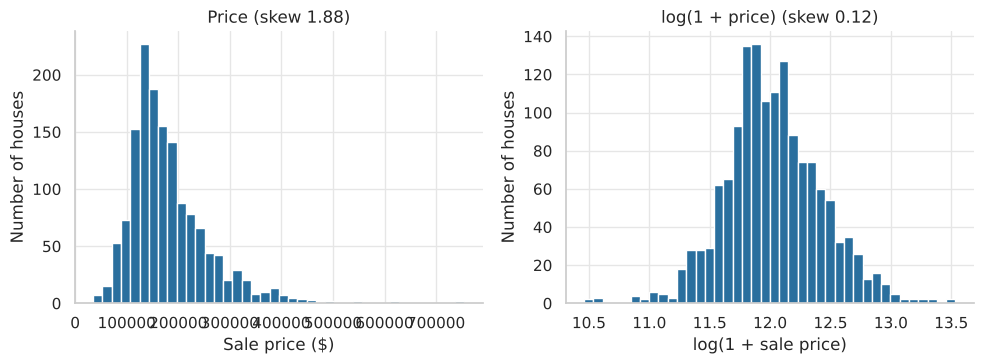

In [10]:
price = df[TARGET]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].hist(price, bins=40, color=BLUE)
axes[0].set_title(f"Price (skew {price.skew():.2f})")
axes[0].set_xlabel("Sale price ($)"); axes[0].set_ylabel("Number of houses")
axes[1].hist(np.log1p(price), bins=40, color=BLUE)
axes[1].set_title(f"log(1 + price) (skew {np.log1p(price).skew():.2f})")
axes[1].set_xlabel("log(1 + sale price)"); axes[1].set_ylabel("Number of houses")
plt.tight_layout(); plt.show()

**What do we learn?**
- Prices are right-skewed (skew **1.88**): most houses sell near the median of **$163,000**, and a thin tail reaches **$755,000**. The mean ($180,921) is pulled above the median by that tail.
- After the log transform the skew drops to **0.12**, almost symmetric. We will model the log of the price in Stage 8 and compare it with the raw price in Stage 11.

### 3.2 Missing values: where are the gaps?
Most models cannot handle blanks, so we need to know where they are and how big they are.

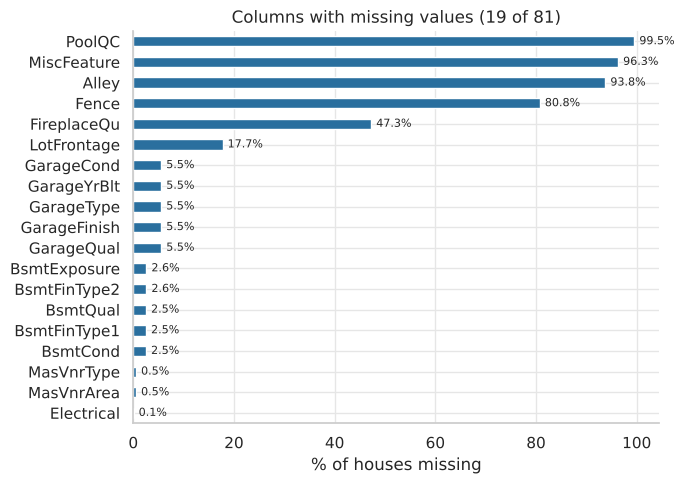

In [11]:
miss = (df.isna().mean() * 100)
miss = miss[miss > 0].sort_values()
ax = miss.plot.barh(color=BLUE, figsize=(7, 5))
ax.set_title(f"Columns with missing values ({len(miss)} of {df.shape[1]})")
ax.set_xlabel("% of houses missing"); ax.set_ylabel("")
for i, v in enumerate(miss): ax.text(v + 1, i, f"{v:.1f}%", va="center", fontsize=8)
plt.tight_layout(); plt.show()

**What do we learn?**
- 19 of 81 columns have gaps. Five are missing in more than 40% of houses: `PoolQC` (99.5%), `MiscFeature`, `Alley`, `Fence` and `FireplaceQu` (47.3%). Thirteen columns are missing in under 6%.
- Almost nobody has a pool, so a missing `PoolQC` most likely means "no pool", not "unknown". Stage 4 will test that idea instead of assuming it.
- `LotFrontage` (17.7%) sits in the middle, and it is the column we will need to impute.

### 3.3 Which features move with price?
**Correlation** is a number from -1 to +1 showing how closely two columns rise and fall together. It only captures *straight-line* relationships, but it is a fast first ranking.

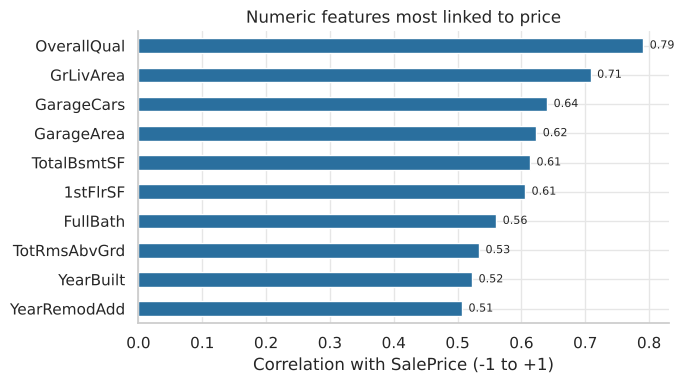

In [12]:
numbers = df.select_dtypes("number").drop(columns=["Id"])
corr = numbers.corr()[TARGET].drop(TARGET)
top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(10)[::-1]
ax = top.plot.barh(color=BLUE, figsize=(7, 4))
ax.set_title("Numeric features most linked to price")
ax.set_xlabel("Correlation with SalePrice (-1 to +1)"); ax.set_ylabel("")
for i, v in enumerate(top): ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

### 3.4 Quality and price
`OverallQual` is a 1 to 10 rating of materials and finish. It topped the list, so let's see the relationship. Each box covers the middle 50% of prices at that quality level, and the dots are unusual houses.

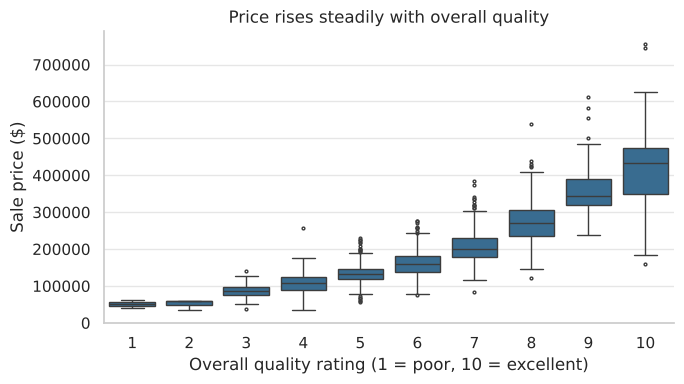

In [13]:
ax = sns.boxplot(data=df, x="OverallQual", y=TARGET, color=BLUE, fliersize=2)
ax.set_title("Price rises steadily with overall quality")
ax.set_xlabel("Overall quality rating (1 = poor, 10 = excellent)"); ax.set_ylabel("Sale price ($)")
plt.tight_layout(); plt.show()

### 3.5 Living area and price: spot the odd ones
Scatter plots reveal houses that break the pattern. We colour any house with more than 4,000 sq ft of living area in orange.

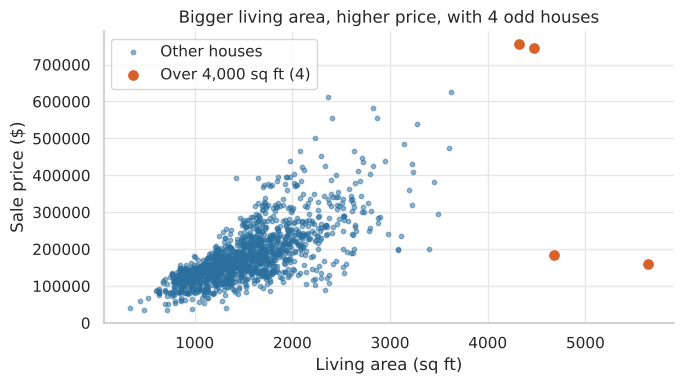

In [14]:
big = df["GrLivArea"] > 4000
plt.scatter(df.loc[~big, "GrLivArea"], price[~big], s=10, alpha=0.5, color=BLUE, label="Other houses")
plt.scatter(df.loc[big, "GrLivArea"], price[big], s=45, color=ORANGE, label=f"Over 4,000 sq ft ({big.sum()})")
plt.title("Bigger living area, higher price, with 4 odd houses")
plt.xlabel("Living area (sq ft)"); plt.ylabel("Sale price ($)"); plt.legend()
plt.tight_layout(); plt.show()

**What do we learn?**
- `OverallQual` (0.79) and `GrLivArea` (0.71) are the strongest links, followed by garage size, basement size and first-floor area (0.61 to 0.64). Nine numeric features correlate *negatively*, but all weakly (the lowest is `KitchenAbvGr` at -0.14).
- Median price climbs from **$108,000** at quality 4 to **$200,141** at 7 and **$432,390** at 10, and the spread widens at high quality. Quality 1 and 2 have only 2 and 3 houses, so ignore those boxes.
- Four houses have over 4,000 sq ft. Two sold for the highest prices in the file ($755,000 and $745,000). Two sold far below the trend ($160,000 at 5,642 sq ft and $184,750 at 4,676 sq ft), and both of those are `Partial` sales. We will decide what to do about them in Stage 4.
- Surprise: these four barely move the overall correlation (0.709 with them, 0.721 without). They matter more to a model that fits a line through the data than to the correlation number.

### 3.6 Neighborhood: location matters
`Neighborhood` is text with 25 values. We show the median price of each, with the number of sales in brackets, because a median from 2 houses means little.

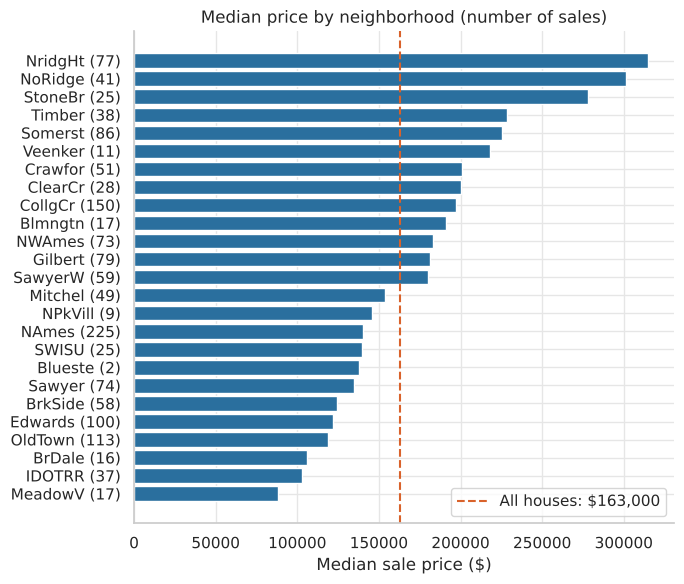

In [15]:
nb = df.groupby("Neighborhood")[TARGET].agg(["median", "count"]).sort_values("median")
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(nb.index + " (" + nb["count"].astype(str) + ")", nb["median"], color=BLUE)
ax.axvline(price.median(), color=ORANGE, linestyle="--", label=f"All houses: ${price.median():,.0f}")
ax.set_title("Median price by neighborhood (number of sales)")
ax.set_xlabel("Median sale price ($)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

### 3.7 Do some features say the same thing twice?
Features that move together (**collinearity**) make linear models unstable, because the model cannot tell which one deserves the credit. The heatmap shows correlations between a few size-related features. Darker means more alike.

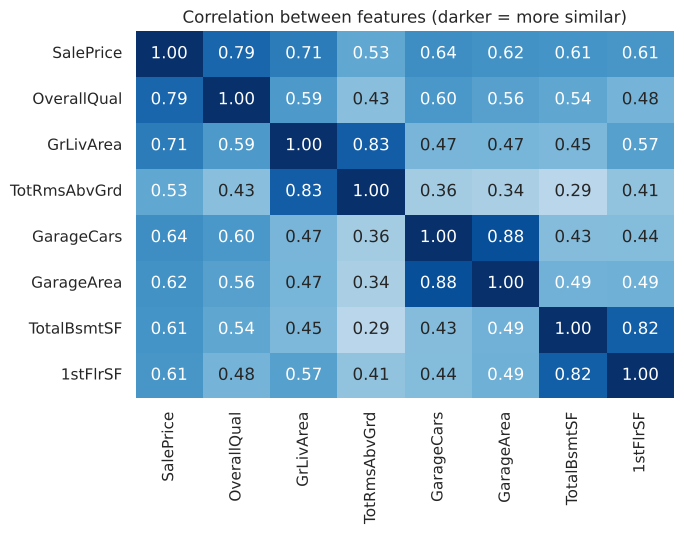

In [16]:
pick = [TARGET, "OverallQual", "GrLivArea", "TotRmsAbvGrd", "GarageCars", "GarageArea", "TotalBsmtSF", "1stFlrSF"]
plt.figure(figsize=(7, 5.5))
sns.heatmap(df[pick].corr(), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False)
plt.title("Correlation between features (darker = more similar)")
plt.tight_layout(); plt.show()

**What do we learn?**
- Median price runs from **$88,000** in MeadowV to **$315,000** in NridgHt, a 3.6x spread. Location is a strong signal, so we must encode `Neighborhood` well. We will meet `TargetEncoder` in Stage 6.
- Some neighborhoods have very few sales: Blueste has 2 and NPkVill has 9. Their medians are unreliable, which is exactly why target encoding needs care.
- Several feature pairs are near-duplicates: `GarageCars` and `GarageArea` (0.88), `GrLivArea` and `TotRmsAbvGrd` (0.83), `TotalBsmtSF` and `1stFlrSF` (0.82). Stage 5 can combine some of them, and Stage 11 shows what this does to Ridge.

*Try it yourself:* Draw the same scatter plot for `LotArea` vs price. Is the relationship as clean as for `GrLivArea`? Which houses stand out?

## Stage 4: Data quality and cleaning

**Key question this stage answers:** Which problems in the data are real, and which only look like problems?

### The one rule that keeps the test set honest
Some cleaning **learns from the data** (for example, "fill gaps with the average"). If it learns from *all* rows, information from the future test set leaks into training. Other cleaning follows **fixed rules** that need nothing from other rows (for example, "no garage, so garage quality is None"). Our rule for this notebook:

| Kind of cleaning | Example | When |
|---|---|---|
| Fixed rule, nothing learned | "No pool, so `PoolQC` is None" | **Now (Stage 4)**, safe before the split |
| Learns a number from the data | "Fill `LotFrontage` with the median" | **Stage 6**, inside the Pipeline, after the split |

### 4.1 Is a missing value really missing?
In Stage 3, `PoolQC` was 99.5% missing. Our idea: a blank means *"this house has no pool"*. We can **test** that idea. Each of these text columns has a number that says whether the feature exists (`PoolArea` for the pool, `GarageArea` for the garage, and so on). If a blank always lines up with a 0 in that number, the blank means "absent".

**What to look for:** the `real gap` column. A non-zero value means a blank we cannot explain.

In [17]:
# Each text column is paired with a number that says the feature does not exist
COMPANION = {"PoolQC": "PoolArea", "MiscFeature": "MiscVal", "FireplaceQu": "Fireplaces",
             "GarageType": "GarageArea", "GarageFinish": "GarageArea", "GarageQual": "GarageArea", "GarageCond": "GarageArea",
             "BsmtQual": "TotalBsmtSF", "BsmtCond": "TotalBsmtSF", "BsmtExposure": "TotalBsmtSF",
             "BsmtFinType1": "TotalBsmtSF", "BsmtFinType2": "TotalBsmtSF"}
rows = []
for col, companion in COMPANION.items():
    gap, none = df[col].isna(), df[companion] == 0
    rows.append({"column": col, "missing": gap.sum(), "feature absent": (gap & none).sum(), "real gap": (gap & ~none).sum()})
print(pd.DataFrame(rows).to_string(index=False))

      column  missing  feature absent  real gap
      PoolQC     1453            1453         0
 MiscFeature     1406            1406         0
 FireplaceQu      690             690         0
  GarageType       81              81         0
GarageFinish       81              81         0
  GarageQual       81              81         0
  GarageCond       81              81         0
    BsmtQual       37              37         0
    BsmtCond       37              37         0
BsmtExposure       38              37         1
BsmtFinType1       37              37         0
BsmtFinType2       38              37         1


**What do we learn?**
- For 10 of the 12 columns, **every** blank lines up with "feature absent". The blank is information: *no pool, no fireplace, no garage, no basement*.
- Two columns hold exactly one real gap each: `BsmtExposure` and `BsmtFinType2`. A basement exists, but one answer was never recorded (a single house each).
- If we had dropped `PoolQC` for being "99.5% missing", we would have thrown away the answer to *does it have a pool?*

### 4.2 Turn the rules into one reusable function
We package the cleaning in a function, `clean_housing`. We will need to run **exactly the same cleaning** on a new house at prediction time in Stage 12. It also never touches the raw `df`, so we can always go back.

In [18]:
def clean_housing(raw):
    """Fixed rules only (nothing is learned from the data), so it is safe to run before the split."""
    out = raw.copy()                                          # never change the raw table
    for col, companion in COMPANION.items():
        absent = out[col].isna() & (out[companion] == 0)      # gap AND the feature does not exist
        out[col] = out[col].astype("object").mask(absent, "None")   # object type also copes with an all-blank column
    for col in ["Alley", "Fence"]:                            # no companion column: we assume missing = none
        out[col] = out[col].astype("object").fillna("None")
    out["MSSubClass"] = out["MSSubClass"].astype(str)         # a code (20, 60, 190...), not a quantity
    return out

df_clean = clean_housing(df)
print("Missing cells:", int(df.isna().sum().sum()), "->", int(df_clean.isna().sum().sum()))

Missing cells: 6965 -> 359


We also changed `MSSubClass` (the building-type code) to text. The numbers 20, 60 and 190 are labels, so "190 is 9.5 times 20" is meaningless, but a model would treat it that way.

### 4.3 What is still missing?
These are the gaps the fixed rules could **not** explain. They need a learned fill value, so they wait for the Pipeline in Stage 6.

In [19]:
left = df_clean.isna().sum()
print(left[left > 0].sort_values(ascending=False).to_string())

LotFrontage     259
GarageYrBlt      81
MasVnrType        8
MasVnrArea        8
BsmtExposure      1
BsmtFinType2      1
Electrical        1


**What do we learn?**
- The rules removed **6,606** of the 6,965 missing cells. Only **359** remain.
- `LotFrontage` (259) is a genuine unknown: every house has a street frontage, we just do not know it. This is the only large real gap.
- `GarageYrBlt` (81) is blank for houses **with no garage**. A year cannot be "None", so Stage 5 will decide: drop it or turn it into a "garage age" feature.
- The remaining few (8, 8, 1, 1, 1) are single-digit gaps. A simple imputer in Stage 6 handles them.

### 4.4 Sanity checks: impossible or suspicious values
Cheap checks for values that cannot be right.

In [20]:
checks = {
    "No bedroom above ground": (df_clean["BedroomAbvGr"] == 0).sum(),
    "No full bathroom": (df_clean["FullBath"] == 0).sum(),
    "Veneer 'None' but area > 0": ((df_clean["MasVnrType"] == "None") & (df_clean["MasVnrArea"] > 0)).sum(),
    "Sold before built": (df_clean["YrSold"] < df_clean["YearBuilt"]).sum(),
    "Remodelled before built": (df_clean["YearRemodAdd"] < df_clean["YearBuilt"]).sum(),
    "Price <= 0": (df_clean[TARGET] <= 0).sum(),
}
print(pd.Series(checks).to_string())

No bedroom above ground       6
No full bathroom              9
Veneer 'None' but area > 0    5
Sold before built             0
Remodelled before built       0
Price <= 0                    0


**What do we learn?**
- The impossible-date and bad-price checks are clean (0 each).
- 6 houses show no above-ground bedroom and 9 no full bathroom. These *might* be real (a bedroom in the basement, a half-bath-only unit), but the data cannot tell us, so we **leave them and note them**. That is 15 rows in 1,460.
- 5 houses say veneer `None` but have a non-zero area, and two of them have an area of just 1 sq ft. That looks like a typing artifact. The effect is tiny, so we leave it.
- **Not every oddity needs fixing.** Fix what is clearly wrong and large. Document the rest.

### 4.5 Outliers: the four huge houses
An **outlier** is a value far from the rest. Not every outlier is an error, so we check each one. We compare price per square foot, because a big house *should* cost more.

In [21]:
big = df_clean[df_clean["GrLivArea"] > 4000]
cols = ["Id", "GrLivArea", "OverallQual", "Neighborhood", "SaleCondition", TARGET]
print(big[cols].assign(price_per_sqft=(big[TARGET] / big["GrLivArea"]).round(0)).to_string(index=False))
print("Typical house: $%.0f per sq ft" % (df_clean[TARGET] / df_clean["GrLivArea"]).median())
outlier_ids = big["Id"].tolist()                  # remember them for the Stage 11 experiment

  Id  GrLivArea  OverallQual Neighborhood SaleCondition  SalePrice  price_per_sqft
 524       4676           10      Edwards       Partial     184750            40.0
 692       4316           10      NoRidge        Normal     755000           175.0
1183       4476           10      NoRidge       Abnorml     745000           166.0
1299       5642           10      Edwards       Partial     160000            28.0
Typical house: $120 per sq ft


**What do we learn?**
- Two houses (Id 692 and 1183) cost **$175 and $166 per sq ft**, above the typical $120. They are quality-10 houses in the same neighborhood, so they look like **genuine expensive sales**.
- Two houses (Id 524 and 1299) cost **$40 and $28 per sq ft**, about a quarter of the typical price. Both are `Partial` sales in Edwards. A `Partial` sale is usually a home that was not completed when sold (our reading, the data does not say so). Their price probably does not describe the finished house.

**Our decision: keep all four in the data for now, and test the choice.** Deleting rows is a one-way door, and the test set should look like the real world. Stage 6 will remove outliers from the **training** rows only if we choose to, and Stage 11 measures what dropping them does.

### 4.6 Verify the cleaning
Finally, check that the function did what we said, including on a **single new house**, as in real use.

In [22]:
for col in ["PoolQC", "Alley", "Fence", "FireplaceQu", "GarageType"]:
    print(f"{col:12s} 'None' = {(df_clean[col] == 'None').sum():5d} of {len(df_clean)} houses")
print("MSSubClass dtype:", df["MSSubClass"].dtype, "->", df_clean["MSSubClass"].dtype)   # whole number -> text
one_house = df.iloc[[0]].copy(); one_house["PoolQC"] = np.nan        # one new house, pool field left blank
print("One-house test, PoolQC becomes:", clean_housing(one_house)["PoolQC"].iloc[0])

PoolQC       'None' =  1453 of 1460 houses
Alley        'None' =  1369 of 1460 houses
Fence        'None' =  1179 of 1460 houses
FireplaceQu  'None' =   690 of 1460 houses
GarageType   'None' =    81 of 1460 houses
MSSubClass dtype: int64 -> str
One-house test, PoolQC becomes: None


**What do we learn?**
- `Alley` is "None" for 1,369 houses and `Fence` for 1,179. These two have no companion number, so "missing means none" is our *assumption*, and we say so.
- The same function works on one new house, which is what Stage 12 needs.

### Summary: what we did and what we deferred

| Problem | Count | Action | Where |
|---|---|---|---|
| Blank means "feature absent" | 6,606 cells | Filled with `None` | **Done (Stage 4)** |
| `MSSubClass` stored as a number | 1 column | Changed to text | **Done (Stage 4)** |
| `LotFrontage` truly unknown | 259 | Imputer learns median from training rows | Stage 6 |
| `GarageYrBlt`, no garage | 81 | Drop or turn into an age | Stage 5 |
| Single-digit real gaps | 19 | Imputer | Stage 6 |
| 4 huge houses | 4 | Flagged in `outlier_ids`, kept | Stage 6 and 11 |
| Zero-bedroom, no-bath, veneer mismatch | 6, 9, 5 | Left as they are | Noted |

---
### Common mistakes (Stage 4)
- **Filling gaps with the mean or median on the whole dataset before splitting.** That leaks test information into training. Learned fills belong in the Pipeline.
- **Dropping a column because it is "99% missing".** Here, missing meant "no pool". Check what a blank means first.
- **Deleting outliers without asking why.** Two of our four were real expensive sales.
- **Cleaning the test set differently from the training set.** Use one function for everything.
- **Overwriting the raw data.** Keep `df` untouched and work on `df_clean`.
- **Treating codes as numbers** (like `MSSubClass`).

*Try it yourself:* Find the single house with a real gap in `BsmtExposure` (hint: `df_clean[df_clean["BsmtExposure"].isna()]`). What is its `Id`, and does it have a basement?

## Stage 5: Feature engineering

**Key question this stage answers:** Can we describe each house in a way that makes the pattern easier for a model to see?

A **feature** is one column the model learns from. **Feature engineering** means reshaping the columns we have: converting, combining and removing them. A model can only use what we show it, so good features often help more than a fancier model.

### The same safety rule as Stage 4
Every step in this stage uses **only the same row** (add two columns, map a rating to a number). Nothing is learned from other rows, so nothing can leak from the test set. Anything that *learns* from the data (scaling, target encoding, imputing) waits for the Pipeline in Stage 6.

| Step | What we do | Why |
|---|---|---|
| 5.1 | Turn ordered ratings into numbers | `Po < Fa < TA < Gd < Ex` has an order. One-hot columns would throw that order away |
| 5.2 | Combine related columns | Features such as *total area* describe a house better than five separate pieces |
| 5.3 | Check the new features | A quick look, with a warning about peeking |
| 5.4 | Drop columns with no information | `Id`, `GarageYrBlt`, and columns where nearly every house has the same value |
| 5.5 | Package everything in one function | Stage 12 must prepare a new house in exactly the same way |

### 5.1 Ordered ratings become numbers
Columns such as `KitchenQual` hold the ratings `Po` (poor), `Fa` (fair), `TA` (typical), `Gd` (good) and `Ex` (excellent). They have a clear order. We give them the scores 1 to 5, and `None` (no such feature, from Stage 4) gets 0.

**What to look for:** does the median price rise with the score? If it does, the order we assumed matches reality.

In [23]:
QUALITY = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
ORDERED = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
           "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]

def score_ratings(data):
    """Turn ordered ratings (Po < Fa < TA < Gd < Ex) into numbers 1-5, and 'None' into 0."""
    out = data.copy()
    for col in ORDERED:
        out[col] = out[col].map(QUALITY)
    return out

df_scored = score_ratings(df_clean)
print(df_clean["KitchenQual"].head(4).tolist(), "->", df_scored["KitchenQual"].head(4).tolist())
print("Median price by KitchenQual score:", df_scored.groupby("KitchenQual")[TARGET].median().to_dict())
print("Ratings left unmapped:", int(df_scored[ORDERED].isna().sum().sum()))

['Gd', 'TA', 'Gd', 'Gd'] -> [4, 3, 4, 4]
Median price by KitchenQual score: {2: 115000.0, 3: 137000.0, 4: 201400.0, 5: 316750.0}
Ratings left unmapped: 0


**What do we learn?**
- `Gd, TA, Gd, Gd` became `4, 3, 4, 4`. Ten text columns are now numbers.
- The median price rises with every step of the score: **$115,000** (score 2) to **$137,000** to **$201,400** to **$316,750** (score 5). The order we assumed is real.
- No rating was left unmapped (0). If a surprise value such as `"Typ"` had appeared, it would have become a blank, so always check.

### 5.2 Combine related columns
Some columns describe one idea in several pieces. A buyer thinks "how big is the house in total?", not "how big is the basement, the first floor and the second floor?". We build seven new features from existing columns:

| New feature | Built from | Idea |
|---|---|---|
| `TotalSF` | basement + first floor + second floor | Total living area |
| `TotalBath` | full baths + 0.5 per half bath, basement included | Total bathrooms |
| `HouseAge` | sale year minus year built | How old at the time of sale |
| `YearsSinceRemodel` | sale year minus remodel year (never below 0) | How fresh is the update |
| `PorchDeckSF` | porches + deck | Outdoor living area |
| `Has2ndFloor`, `WasRemodeled` | yes/no flags | Simple yes/no facts |

In [24]:
def add_features(data):
    """Combine columns using only the same row (nothing learned), so it is safe before the split."""
    out = data.copy()
    out["TotalSF"] = out["TotalBsmtSF"] + out["1stFlrSF"] + out["2ndFlrSF"]
    out["TotalBath"] = out["FullBath"] + 0.5 * out["HalfBath"] + out["BsmtFullBath"] + 0.5 * out["BsmtHalfBath"]
    out["HouseAge"] = out["YrSold"] - out["YearBuilt"]
    out["YearsSinceRemodel"] = (out["YrSold"] - out["YearRemodAdd"]).clip(lower=0)
    out["PorchDeckSF"] = out[["OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch", "WoodDeckSF"]].sum(axis=1)
    out["Has2ndFloor"] = (out["2ndFlrSF"] > 0).astype(int)
    out["WasRemodeled"] = (out["YearRemodAdd"] != out["YearBuilt"]).astype(int)
    return out

df_feat = add_features(df_scored)
new_cols = ["TotalSF", "TotalBath", "HouseAge", "YearsSinceRemodel", "PorchDeckSF", "Has2ndFloor", "WasRemodeled"]
print(df_feat[new_cols].describe().loc[["min", "50%", "max"]].round(1).to_string())
print("Houses sold before their remodel year:", int((df_feat["YrSold"] < df_feat["YearRemodAdd"]).sum()))

     TotalSF  TotalBath  HouseAge  YearsSinceRemodel  PorchDeckSF  Has2ndFloor  WasRemodeled
min    334.0        1.0       0.0                0.0          0.0          0.0           0.0
50%   2474.0        2.0      35.0               14.0        164.0          0.0           0.0
max  11752.0        6.0     136.0               60.0       1027.0          1.0           1.0
Houses sold before their remodel year: 1


**What do we learn?**
- The values look sensible: the median house has **2,474 sq ft** in total (range 334 to 11,752), **2 bathrooms** (1 to 6), and is **35 years old** (0 to 136).
- One house was sold *before* its recorded remodel year, which would give a negative number. We set the minimum to 0 with `clip(lower=0)`. We do not know why (a listing error, or a remodel finished after the sale), and one row cannot matter much.
- Every new feature uses only that house's own columns, so the same code works on a single new house.

### 5.3 Are the new features any good?
We compare each new feature with its closest original, using correlation with price. **A warning about peeking:** if we choose features because they correlate with the *whole* dataset's prices, we are using information the test set contributed. Treat this table as intuition only. The honest test is cross-validation on the training rows, in Stage 8.

In [25]:
pairs = {"TotalSF": "GrLivArea", "TotalBath": "FullBath", "HouseAge": "YearBuilt"}
corr = df_feat.corr(numeric_only=True)[TARGET]
table = pd.DataFrame({"new feature": list(pairs), "corr with price": [corr[n] for n in pairs],
                      "closest original": list(pairs.values()), "original corr": [corr[o] for o in pairs.values()]})
print(table.round(2).to_string(index=False))
print("Others:", corr[["YearsSinceRemodel", "PorchDeckSF", "Has2ndFloor", "WasRemodeled"]].round(2).to_dict())

new feature  corr with price closest original  original corr
    TotalSF             0.78        GrLivArea           0.71
  TotalBath             0.63         FullBath           0.56
   HouseAge            -0.52        YearBuilt           0.52
Others: {'YearsSinceRemodel': -0.51, 'PorchDeckSF': 0.39, 'Has2ndFloor': 0.14, 'WasRemodeled': -0.02}


**What do we learn?**
- `TotalSF` (**0.78**) is more closely linked to price than the best single area, `GrLivArea` (0.71). `TotalBath` (**0.63**) beats `FullBath` (0.56). Combining helped.
- `HouseAge` has a **negative** correlation, **-0.52**: older houses sell for less. It is `YearBuilt` (0.52) turned upside down, so it adds little new information. It is easier to read, though, and a good example of a negative correlation.
- `YearsSinceRemodel` (-0.51) points the same way. `PorchDeckSF` (0.39) is a moderate signal. `WasRemodeled` (-0.02) shows almost nothing on its own, so we keep it only because it costs nothing, and we let the model decide.
- Several new features overlap with the originals (`TotalSF` with `GrLivArea`, `HouseAge` with `YearBuilt`). We **keep the originals** for now and test the overlap in Stage 11.

### 5.4 Drop columns that carry no information
- `Id` is just a row number. If a model learns from it, it learns noise.
- `GarageYrBlt` overlaps with `YearBuilt` (correlation 0.83, from Stage 3) and is blank for the 81 houses with no garage. We drop it.
- **Near-constant columns:** if one value covers 95% or more of the houses, the column cannot separate cheap from expensive houses. We check the text columns.

In [26]:
text_cols = df_feat.select_dtypes(exclude="number").columns
top_share = df_feat[text_cols].apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100).sort_values(ascending=False)
NEAR_CONSTANT = top_share[top_share >= 95].index.tolist()       # one value covers 95%+ of houses
print(top_share.head(8).round(1).to_string())
print("Dropping:", NEAR_CONSTANT)

Utilities      99.9
Street         99.6
Condition2     99.0
RoofMatl       98.2
Heating        97.8
MiscFeature    96.3
LandSlope      94.7
Alley          93.8
Dropping: ['Utilities', 'Street', 'Condition2', 'RoofMatl', 'Heating', 'MiscFeature']


**What do we learn?**
- Six columns pass the 95% test: `Utilities` (99.9%), `Street` (99.6%), `Condition2` (99.0%), `RoofMatl` (98.2%), `Heating` (97.8%) and `MiscFeature` (96.3%). `LandSlope` (94.7%) just misses. The 95% line is a judgment call, not a law.
- **A small caveat:** we measured these shares on all 1,460 houses. It used only the *features*, never the price, so the risk is tiny. The strictest approach would measure it on the training rows only.
- Pool quality is another near-constant (1,453 of 1,460 houses have no pool), but it is now a number. We leave it, since the pool's size is also in `PoolArea`.

### 5.5 One function for the whole preparation
We chain the Stage 4 cleaning, the rating scores and the new features into **one function**. Training and prediction must prepare a house *identically*, and one function guarantees that. We also split off the target (`y`) and keep `Id` aside.

In [27]:
DROP_COLS = ["Id", "GarageYrBlt"] + NEAR_CONSTANT
def prepare_features(raw):
    """Raw rows in, model-ready features out. Same chain for training and for a new house."""
    out = add_features(score_ratings(clean_housing(raw)))
    return out.drop(columns=DROP_COLS + [TARGET], errors="ignore")

ids = df["Id"]                                     # keep Id aside so we can find the outliers later
X, y = prepare_features(df), df[TARGET]
print("X:", X.shape, "| y:", y.shape)
print("numeric:", X.select_dtypes("number").shape[1], "| text:", X.select_dtypes(exclude="number").shape[1])
left = X.isna().sum(); print("Still missing:", left[left > 0].to_dict())

X: (1460, 79) | y: (1460,)
numeric: 51 | text: 28
Still missing: {'LotFrontage': 259, 'MasVnrType': 8, 'MasVnrArea': 8, 'BsmtExposure': 1, 'BsmtFinType2': 1, 'Electrical': 1}


**What do we learn?**
- `X` has **1,460 rows and 79 features**: 51 numeric and 28 text. The target `y` is separate.
- Six columns still have blanks: `LotFrontage` (259), `MasVnrType` (8), `MasVnrArea` (8), `BsmtExposure` (1), `BsmtFinType2` (1) and `Electrical` (1). That is 278 blank cells, all for the Pipeline's imputer in Stage 6.
- The 28 text columns will be encoded in Stage 6, inside the Pipeline.

### 5.6 Does it work on a brand-new house?
At prediction time, a new house arrives with **no `SalePrice`**. The function must cope with that, and must produce the same columns, in the same order, as the training data.

In [28]:
new_house = df.drop(columns=[TARGET]).iloc[[0]]      # no SalePrice column, like a real new listing
features = prepare_features(new_house)
print("New house ->", features.shape, "| TotalSF:", features["TotalSF"].iloc[0], "| HouseAge:", features["HouseAge"].iloc[0])
print("Same columns as training X:", features.columns.tolist() == X.columns.tolist())

New house -> (1, 79) | TotalSF: 2566 | HouseAge: 5
Same columns as training X: True


**What do we learn?**
- A single house goes through the whole chain: 1 row, 79 features, `TotalSF` 2,566 and `HouseAge` 5, the same columns in the same order as `X`.
- `HouseAge` uses `YrSold`. At prediction time we will set it to the current year, a point we revisit in Stage 12.

### Summary

| Change | Detail | Result |
|---|---|---|
| Ratings to numbers | 10 columns, scores 0 to 5 | Order kept, no new columns |
| New features | `TotalSF`, `TotalBath`, `HouseAge`, `YearsSinceRemodel`, `PorchDeckSF`, `Has2ndFloor`, `WasRemodeled` | +7 columns |
| Dropped | `Id`, `GarageYrBlt`, 6 near-constant columns | -8 columns |
| Left for the Pipeline | blanks, scaling, text encoding | Stage 6 |

*Try it yourself:* Add one more feature inside `add_features`: `out["LotToHouse"] = out["LotArea"] / out["TotalSF"]` (how big the lot is compared with the house). Does `prepare_features(df)` still run, and how many columns does `X` have now? Then answer: why must you never build a feature from `SalePrice`?

## Stage 6: Split and Pipeline

**Key question this stage answers:** How do we keep a test set that is honest, and build preprocessing that cannot leak into it?

### The exam analogy
A student who sees the exam questions while studying will score well and prove nothing. A model is the same. We lock away **20% of the houses (the test set)** and never look at them until Stage 10. The other 80% (the **training set**) is where the model learns.

**Leakage** means information from the test set sneaking into training. It makes the final score look better than reality, and it is easy to do by accident. The usual culprits are steps that *learn from data*: filling blanks with the median, scaling numbers, and converting categories into numbers. If they learn from all the houses, the test houses have already "talked" to the model.

The cure is a **Pipeline**: one object that chains the preprocessing and the model. When we call `fit` on the training rows, *every* step learns from the training rows only. When we later score new houses, it applies what it learned and learns nothing new.

### 6.1 Split first
We split **before** anything else is learned. `random_state=42` makes the split repeatable.

In [29]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Median price  train: $%s | test: $%s" % (f"{y_train.median():,.0f}", f"{y_test.median():,.0f}"))
id_train, id_test = ids.loc[X_train.index], ids.loc[X_test.index]
print("Outlier houses in train:", id_train[id_train.isin(outlier_ids)].tolist(), "| in test:", id_test[id_test.isin(outlier_ids)].tolist())

Train: (1168, 79) | Test: (292, 79)
Median price  train: $165,000 | test: $154,150
Outlier houses in train: [1183, 524, 1299] | in test: [692]


**What do we learn?**
- 1,168 houses to learn from and 292 held back. From here on, `X_test` and `y_test` are **sealed** until Stage 10.
- The test median ($154,150) is lower than the training median ($165,000). A random split of 292 houses will not match perfectly, and we cannot "fix" it by peeking.
- **Three of our four big-house outliers are in training, and Id 692, the $755,000 house, is in the test set.** That one will be hard to predict, and it will count against our Stage 10 score. We keep it in, because a real buyer could bring us a house like it.
- The outlier decision from Stage 4 stands: we **keep** the three training outliers for now. Stage 11 measures what dropping them does.

One honest caveat: our houses were sold over 2006 to 2010, and a random split mixes the years. A real price tool predicts the *future*. Stage 13 looks at how the model ages.

### 6.2 Group the columns by what they need
Different columns need different preprocessing:

| Group | What it needs | Why |
|---|---|---|
| **Numeric** | Fill blanks with the median, then rescale | Blanks break most models. Rescaling puts "square feet" and "bathrooms" on a common footing |
| **Text, few values** | Fill blanks with the most common value, then **one-hot encode** | One-hot makes one yes/no column per value. Fine for 3 to 9 values |
| **Text, many values** | Fill blanks, then **target encode** | One-hot on 25 neighborhoods would add 25 columns. Target encoding uses 1 column |

In [30]:
num_cols = X_train.select_dtypes("number").columns.tolist()
text_cols = X_train.select_dtypes(exclude="number").columns.tolist()
high_cols = [c for c in text_cols if X_train[c].nunique() > 10]       # many values: one-hot would explode
low_cols = [c for c in text_cols if c not in high_cols]
print("numeric:", len(num_cols), "| text, few values:", len(low_cols))
print("text, many values:", {c: X_train[c].nunique() for c in high_cols})

numeric: 51 | text, few values: 24
text, many values: {'MSSubClass': 15, 'Neighborhood': 25, 'Exterior1st': 15, 'Exterior2nd': 16}


**What do we learn?**
- 51 numeric columns, 24 text columns with few values, and 4 with many: `MSSubClass` (15), `Neighborhood` (25), `Exterior1st` (15) and `Exterior2nd` (16).
- We counted values on the **training** rows only, even for this small decision.

### 6.3 Target encoding, and a trap
**Target encoding** replaces each category with the **average price of that category** in the training data. For example, `NridgHt` becomes about $315,000. One number per house, and it keeps the signal from the target.

**The leakage risk:** the encoding is built from the *prices*. If a house's own price helps build its own encoding, the model has been handed the answer. Scikit-learn protects the training rows: during `fit` it computes each house's encoding using **cross-fitting** (5 folds, so a house is encoded from the *other* folds). But that only works if we use it **inside the Pipeline, fitted on training rows**.

**A second trap.** `TargetEncoder` has a setting `target_type="auto"`. It looks at the target and guesses whether it is a *category* or a *number*. Let's see what it guesses for our price.

In [31]:
from sklearn.utils.multiclass import type_of_target
from sklearn.preprocessing import TargetEncoder
print("scikit-learn reads our price as:", type_of_target(y_train))
guess = TargetEncoder(random_state=RANDOM_STATE).fit_transform(X_train[["Neighborhood"]], y_train)
fixed = TargetEncoder(target_type="continuous", random_state=RANDOM_STATE).fit_transform(X_train[["Neighborhood"]], y_train)
print("Columns made from ONE text column -> auto:", guess.shape[1], "| continuous:", fixed.shape[1])
print("Distinct prices in the training set:", y_train.nunique())

scikit-learn reads our price as: multiclass


Columns made from ONE text column -> auto: 571 | continuous: 1
Distinct prices in the training set: 571


**What do we learn?**
- Scikit-learn reads our price as **`multiclass`**, as if each distinct price were a separate category, because prices are whole numbers. With `auto`, **one** text column becomes **571 columns**, one per distinct price. Everything would run and give no error, but the model would be buried in useless columns.
- Telling it `target_type="continuous"` gives **1** column, as intended.
- **Lesson:** a silent default can wreck a model. Always check the shape of what comes out.

### 6.4 Build the preprocessor
A `ColumnTransformer` applies a different recipe to each group of columns and puts the results side by side. Each recipe is itself a small `Pipeline` of steps. `handle_unknown="ignore"` stops a category that appears only in new data from crashing the model. `add_indicator=True` adds a yes/no flag column for any numeric column that had blanks in the training rows, so the model can notice that a value was filled in.

In [32]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer([
    ("num", Pipeline([("fill", SimpleImputer(strategy="median", add_indicator=True)),
                      ("scale", StandardScaler())]), num_cols),
    ("low", Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), low_cols),
    ("high", Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                       ("target", TargetEncoder(target_type="continuous", random_state=RANDOM_STATE))]), high_cols),
])
print("Built (not fitted yet):", [name for name, _, _ in preprocessor.transformers])

Built (not fitted yet): ['num', 'low', 'high']


### 6.5 Fit it on the training rows only
`fit_transform(X_train, y_train)` makes the preprocessor **learn** (the medians, the scaling, the category lists, the average prices) from the training rows and then converts them. We never fit it on `X_test`.

In [33]:
Z = preprocessor.fit_transform(X_train, y_train)          # learn from the training rows only
print("Before:", X_train.shape, "-> After:", Z.shape, "| blanks left:", int(np.isnan(Z).sum()))
print(pd.Series(preprocessor.get_feature_names_out()).str.split("__").str[0].value_counts().to_dict())

Before: (1168, 79) -> After: (1168, 185) | blanks left: 0
{'low': 128, 'num': 53, 'high': 4}


**What do we learn?**
- 79 columns became **185**, and no blanks are left.
- The 185 break down as **53** from the numeric group (51 columns plus 2 "was blank" flags, for `LotFrontage` and `MasVnrArea`), **128** one-hot columns, and **4** target-encoded columns. Nothing exploded.

### 6.6 The leakage demo: wrong versus right
We must not touch the test set, so we practise on a **throwaway split inside the training rows**: 75% to learn, 25% as a stand-in test. We compare two ways of doing the same job:

- **Wrong:** fit the preprocessor on *all* the training rows, including the stand-in test rows and their prices, then split.
- **Right:** a Pipeline fitted only on the 75%.

In [34]:
from sklearn.base import clone
from sklearn.linear_model import Ridge
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=RANDOM_STATE)
wrong_prep = clone(preprocessor).fit(X_train, y_train)            # WRONG: has seen the validation rows and prices
wrong_model = Ridge(alpha=10).fit(wrong_prep.transform(X_fit), y_fit)
right_pipe = Pipeline([("prep", clone(preprocessor)), ("model", Ridge(alpha=10))]).fit(X_fit, y_fit)   # RIGHT
print(pd.DataFrame([report(y_val, wrong_model.predict(wrong_prep.transform(X_val)), "wrong: prep saw validation"),
                    report(y_val, right_pipe.predict(X_val), "right: Pipeline")]).to_string(index=False))

                     model  MAE ($)  RMSE ($)    R2
wrong: prep saw validation    20543     29678 0.853
           right: Pipeline    20521     29734 0.852


**What do we learn?**
- The two scores are almost identical: R² **0.853** (wrong) against **0.852** (right). The wrong version is even slightly worse on MAE ($20,543 against $20,521). These tiny differences are noise.
- **This is the honest surprise: with these tame features, the leak is invisible.** That is exactly why leakage is dangerous. Nothing warns you, and the number looks fine.
- The leak matters most with **rare categories**. The next cell shows the extreme case.

### 6.7 The extreme case: a category that is unique to each house
Imagine a text column that is nearly unique to each house, like a street address. Its "average price" is just *that house's price*. We build a made-up `HouseCode` for each house and target-encode it by itself, once the wrong way (the encoder has seen the stand-in test prices) and once the right way (training rows only).

In [35]:
code = pd.DataFrame({"HouseCode": X_train.index.astype(str)}, index=X_train.index)      # a unique code per house
enc_wrong = TargetEncoder(target_type="continuous", random_state=RANDOM_STATE).fit(code, y_train)               # saw ALL prices
enc_right = TargetEncoder(target_type="continuous", random_state=RANDOM_STATE).fit(code.loc[X_fit.index], y_fit) # saw fit rows only
for name, enc in [("wrong", enc_wrong), ("right", enc_right)]:
    model = Ridge(alpha=1).fit(enc.transform(code.loc[X_fit.index]), y_fit)
    print(report(y_val, model.predict(enc.transform(code.loc[X_val.index])), name).to_dict())

{'model': 'wrong', 'MAE ($)': 0, 'RMSE ($)': 0, 'R2': 1.0}
{'model': 'right', 'MAE ($)': 57794, 'RMSE ($)': 77389, 'R2': -0.0}


**What do we learn?**
- The wrong version is **perfect**: MAE $0, R² 1.0. It "predicts" every price exactly because the encoder was handed those prices. No real model can do that.
- The right version scores R² **0.0** with MAE **$57,794**, which is what a column with no real information deserves. The encoder has never seen these houses, so it falls back to the average price.
- **A score that looks too good is a warning, not a prize.** Ask where it came from.
- `HouseCode` is invented to make the point. Rare categories (a seller with two sales, a street with one house) behave like a weak version of the same trap.

### 6.8 One reusable pipeline
Finally we wrap "preprocessor + any model" in a small function, so Stages 7 to 10 can swap models without touching the preprocessing. Fitting it on `X_train` is the only learning step.

In [36]:
def build_pipeline(model):
    """Preprocessing + any model in one object. A fresh copy of the preprocessor each time."""
    return Pipeline([("prep", clone(preprocessor)), ("model", model)])

pipe = build_pipeline(Ridge(alpha=10)).fit(X_train, y_train)
print("Steps:", [name for name, _ in pipe.steps])
print("3 training houses, predicted:", pipe.predict(X_train.head(3)).round(-3).tolist(), "| actual:", y_train.head(3).tolist())
print("Test set still sealed:", X_test.shape)

Steps: ['prep', 'model']
3 training houses, predicted: [133000.0, 184000.0, 91000.0] | actual: [145000, 178000, 85000]
Test set still sealed: (292, 79)


**What do we learn?**
- A pipeline with two named steps, `prep` and `model`, fits in one call and predicts straight from raw columns: no manual conversion.
- It predicts $133,000, $184,000 and $91,000 for houses that sold for $145,000, $178,000 and $85,000. These are houses it **trained on**, so this is a smoke test, not a score. We have not scored the test set, and we will not until Stage 10.

### Summary

| Piece | What it does | Learned from |
|---|---|---|
| `train_test_split` | Seals 292 houses away | Nothing (random, `random_state=42`) |
| Numeric recipe | Median fill, flag, rescale | Training rows only |
| Low-cardinality text recipe | Most-common fill, one-hot | Training rows only |
| High-cardinality text recipe | Most-common fill, target encoding (continuous) | Training rows only |
| `build_pipeline(model)` | Preprocessing + any model | Reused in Stages 7 to 10 |

---
### Common mistakes (Stage 6)
- **Fitting the imputer, scaler or encoder on all the data and then splitting.** The test houses influence the training.
- **Calling `fit` on a `TargetEncoder` with all rows, then `transform`.** This is the leak from 6.7. Keep it inside the Pipeline.
- **Leaving `target_type="auto"` with whole-number prices.** One text column became 571 columns, with no error.
- **Peeking at the test score while tuning.** Every look makes the test set a little less honest. We look once, in Stage 10.
- **Choosing features by their correlation with all the prices.** That is a quiet form of peeking too.
- **Forgetting `handle_unknown="ignore"`.** One new neighborhood in new data would crash the one-hot encoder.
- **Skipping `random_state`.** The split changes on every run, and nobody can reproduce your numbers.

*Try it yourself:* Change `test_size` to `0.3` in 6.1. What are the new train and test shapes? Then change `random_state` to `7` and look at the test median. How much does it move?

## Stage 7: Baseline models

**Key question this stage answers:** How well do the simplest possible models do, so we can tell whether anything fancier is worth the effort?

A **baseline** is a deliberately simple model that sets the floor. Every later model must beat it, or it is not an improvement. We climb in four small steps:

| Step | Model | What it knows |
|---|---|---|
| 1 | Dummy (median) and Dummy (mean) | Nothing about the house, just one fixed price |
| 2 | Straight line on `TotalSF` | Only the size |
| 3 | Straight line on `TotalSF` + `OverallQual` | Size and quality |
| 4 | **Ridge** on all 79 features | Everything, through our Stage 6 pipeline |

### How we score: 5-fold cross-validation
One score from one split is noisy (Stage 6 showed a swing of about $8,300 in the median alone). **Cross-validation (CV)** fixes this. We cut the 1,168 training houses into **5 piles ("folds")**. Five times, we train on 4 piles and score on the pile we held out. We then average the five scores. The `MAE spread` column is how much the five scores vary.

**The test set is not used here.** Everything below happens inside the training rows. `shuffle=True` and `random_state=42` make the 5 piles the same on every run, so every model faces the same 5 mini-exams.

**What to look for:** MAE and RMSE in dollars (lower is better), R² (higher is better, 0 means "no better than guessing the average").

In [37]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_validate, cross_val_predict
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)       # the same 5 piles for every model

def score_model(model, name):
    """5-fold cross-validation on the TRAINING rows only. MAE and RMSE in dollars, plus R2 and fit time."""
    out = cross_validate(model, X_train, y_train, cv=cv,
                         scoring={"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"})
    return pd.Series({"model": name, "MAE ($)": round(-out["test_mae"].mean()), "MAE spread": round(out["test_mae"].std()),
                      "RMSE ($)": round(-out["test_rmse"].mean()), "R2": round(out["test_r2"].mean(), 3),
                      "fit s": round(out["fit_time"].mean(), 2)})

results = [score_model(DummyRegressor(strategy="median"), "Dummy (median)")]
print(pd.DataFrame(results).to_string(index=False))

         model  MAE ($)  MAE spread  RMSE ($)     R2  fit s
Dummy (median)    54586        2677     78860 -0.046    0.0


**What do we learn?**
- The dummy that always says "the median price" is off by **$54,586** on average (MAE). That is our **floor**: about a third of a typical house price. Any real model must beat it.
- Its R² is **-0.046**, slightly below zero, which means a little *worse* than guessing the average.

### 7.2 The other dummy
The median and the mean are both "one fixed number". On skewed prices (Stage 3) they differ, so we score both.

In [38]:
results.append(score_model(DummyRegressor(strategy="mean"), "Dummy (mean)"))
print(pd.DataFrame(results).to_string(index=False))

         model  MAE ($)  MAE spread  RMSE ($)     R2  fit s
Dummy (median)    54586        2677     78860 -0.046    0.0
  Dummy (mean)    56318        2612     77160 -0.002    0.0


**What do we learn?**
- The mean dummy scores R² **-0.002**, which is essentially zero. R² is defined against "always guess the average", so this is what "no information" looks like. The median dummy is slightly negative because the median is not the average.
- The mean is worse on MAE ($56,318) but better on RMSE ($77,160 against $78,860). The mean sits closer to the expensive houses, which RMSE punishes hardest. **The metric you choose changes which "winner" you see.**
- We use the **median dummy** ($54,586 MAE) as the bar to beat, since MAE is our main metric.

### 7.3 Simple straight lines
A **linear regression** fits a straight line (or flat plane) through the data: price = a number times the size, plus a number. We try two tiny models to see how far one or two features go. `only()` keeps just the chosen columns, so the model sees nothing else.

In [39]:
from sklearn.linear_model import LinearRegression
def only(cols):
    """Keep just these columns, so the model sees nothing else."""
    return ColumnTransformer([("keep", "passthrough", cols)])

size_only = Pipeline([("pick", only(["TotalSF"])), ("model", LinearRegression())])
size_quality = Pipeline([("pick", only(["TotalSF", "OverallQual"])), ("model", LinearRegression())])
results.append(score_model(size_only, "Line: TotalSF only"))
results.append(score_model(size_quality, "Line: TotalSF + OverallQual"))
print(pd.DataFrame(results).to_string(index=False))

                      model  MAE ($)  MAE spread  RMSE ($)     R2  fit s
             Dummy (median)    54586        2677     78860 -0.046   0.00
               Dummy (mean)    56318        2612     77160 -0.002   0.00
         Line: TotalSF only    32115        2057     49959  0.575   0.01
Line: TotalSF + OverallQual    26201        1524     40761  0.718   0.00


**What do we learn?**
- **One number, the total size, cuts the error from $54,586 to $32,115** and gives R² **0.575**. Size alone explains more than half of the price variation.
- Adding the quality rating helps again: MAE **$26,201**, R² **0.718**.
- Both lines are **instant to fit** (well under a hundredth of a second), and they are easy to explain to a buyer. Keep that in mind for Stage 11.

### 7.4 Ridge on everything
**Ridge** is linear regression with a penalty that stops any one feature from getting an extreme weight. That matters here, because many of our 185 prepared columns overlap (`TotalSF` and `GrLivArea`, for example). The penalty strength is called **`alpha`**. We use the default (1.0) and **do not tune it yet**: tuning is Stage 9. We feed it through our Stage 6 pipeline, so it uses all 79 features.

In [40]:
from sklearn.linear_model import Ridge
results.append(score_model(build_pipeline(Ridge()), "Ridge: all 79 features"))
print(pd.DataFrame(results).to_string(index=False))

                      model  MAE ($)  MAE spread  RMSE ($)     R2  fit s
             Dummy (median)    54586        2677     78860 -0.046   0.00
               Dummy (mean)    56318        2612     77160 -0.002   0.00
         Line: TotalSF only    32115        2057     49959  0.575   0.01
Line: TotalSF + OverallQual    26201        1524     40761  0.718   0.00
     Ridge: all 79 features    21818         462     34697  0.794   0.03


**What do we learn?**
- Ridge on all features reaches MAE **$21,818**, RMSE **$34,697** and R² **0.794**.
- **The honest picture is diminishing returns.** The error falls from $54.6k to $32.1k to $26.2k to $21.8k. The last step used 77 more features to gain only **$4,383** over the two-feature line.
- The `MAE spread` shrinks from $2,057 and $1,524 for the line models to **$462** for Ridge, so its score is much more stable from fold to fold.
- RMSE ($34,697) is well above MAE ($21,818), which means a few **very large misses** pull it up. We look at those next.
- Ridge's default `alpha` is not tuned. As a preview, `alpha=10` gives MAE $20,886 and R² 0.805, but we leave real tuning for Stage 9.

### 7.5 Where does the baseline go wrong?
`cross_val_predict` gives every training house a prediction from a model that **never saw that house**. We plot predicted against actual. A perfect model would put every dot on the dashed diagonal.

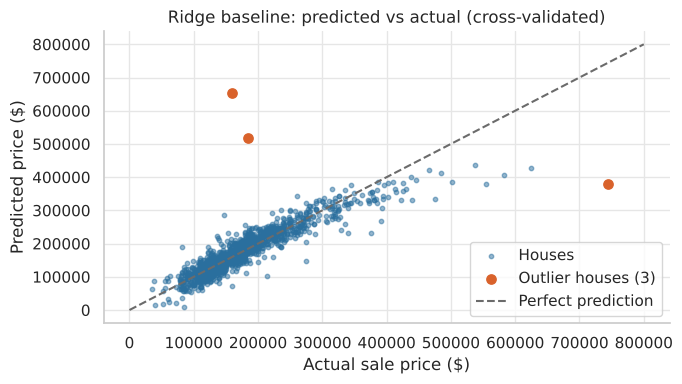

Houses above $400k: 21 | predicted too low: 21 | average shortfall: $98,979


In [41]:
import matplotlib.pyplot as plt
pred = cross_val_predict(build_pipeline(Ridge()), X_train, y_train, cv=cv)      # each house predicted by a model that never saw it
is_big = ids.loc[X_train.index].isin(outlier_ids).values                         # the big-house outliers from Stage 4
plt.scatter(y_train[~is_big], pred[~is_big], s=10, alpha=0.5, color="#2A6F9E", label="Houses")
plt.scatter(y_train[is_big], pred[is_big], s=45, color="#D9622B", label="Outlier houses (3)")
lims = [0, 800_000]; plt.plot(lims, lims, color="#6B6B6B", linestyle="--", label="Perfect prediction")
plt.title("Ridge baseline: predicted vs actual (cross-validated)")
plt.xlabel("Actual sale price ($)"); plt.ylabel("Predicted price ($)"); plt.legend()
plt.tight_layout(); plt.show()
top = (y_train > 400_000).values                                                  # the most expensive houses
print(f"Houses above $400k: {top.sum()} | predicted too low: {(pred[top] < y_train.values[top]).sum()} | average shortfall: ${(y_train.values[top] - pred[top]).mean():,.0f}")

**What do we learn?**
- Most dots hug the diagonal, so the baseline captures the main pattern.
- The three orange dots are the **big-house outliers** from Stage 4, and they miss in both directions. The two cheap, unfinished `Partial` sales (Ids 1299 and 524, which sold for $160,000 and $184,750) are predicted at about **$654,000 and $518,000**, far too high. The $745,000 house (Id 1183) is predicted at about **$379,000**, far too low.
- **A pattern, not noise:** *every one* of the houses above $400,000 is predicted too low, by about **$99,000** on average (the number printed above). A straight line fitted to raw prices flattens out at the top end. Stage 8 tests whether a log target or a non-linear model fixes this.

### 7.6 Who gets the biggest errors?
We split the training houses into three equal groups by actual price, and look at the error in dollars and as a percentage of the price. We also list the five biggest misses.

In [42]:
err = pd.Series(np.abs(pred - y_train.values), index=y_train.index)
group = pd.qcut(y_train, 3, labels=["cheapest third", "middle third", "priciest third"])
by_group = pd.DataFrame({"MAE ($)": err.groupby(group).mean().round(),
                         "error as % of price": (err / y_train).groupby(group).mean().mul(100).round(1)})
print(by_group.to_string())
print("MAE as % of the median price:", round(err.mean() / y_train.median() * 100, 1))
print("Five biggest misses (Id: $ off):", err.set_axis(ids.loc[err.index].values).nlargest(5).round(-3).astype(int).to_dict())

                MAE ($)  error as % of price
SalePrice                                   
cheapest third  18921.0                 17.8
middle third    20571.0                 12.4
priciest third  25987.0                  9.1
MAE as % of the median price: 13.2
Five biggest misses (Id: $ off): {1299: 494000, 1183: 366000, 524: 334000, 1170: 197000, 804: 177000}


**What do we learn?**
- In **dollars**, the priciest third has the largest error ($25,987 against $18,921 for the cheapest). In **percent**, it is the reverse: **17.8%** for the cheapest third against **9.1%** for the priciest. A $19,000 miss on a $100,000 house hurts far more than a $26,000 miss on a $400,000 one. **Stage 11 returns to this.**
- Overall, MAE is **13.2%** of the median price. A buyer should read our prediction as "roughly plus or minus 13%".
- **Three of the five biggest misses are the outlier houses** from Stage 4 (Ids 1299, 1183 and 524), off by $494,000, $366,000 and $334,000. They are only 3 of 1,168 houses, but they inflate RMSE. Stage 11 tests dropping them.

### Summary

| Model | MAE ($) | R² | What it tells us |
|---|---|---|---|
| Dummy (median) | 54,586 | -0.046 | The floor |
| Line: TotalSF only | 32,115 | 0.575 | Size alone is powerful |
| Line: TotalSF + OverallQual | 26,201 | 0.718 | Quality adds a lot |
| **Ridge: all 79 features** | **21,818** | **0.794** | **Our baseline to beat in Stage 8** |

*Try it yourself:* In 7.4, change `Ridge()` to `Ridge(alpha=10)` and re-run. Does the MAE go down? By how much? (Stage 9 will tune `alpha` properly, so do not treat this as the final answer.)

## Stage 8: Better models with cross-validation

**Key question this stage answers:** Can smarter models, and a smarter way of handling the price, beat our Ridge baseline, and by how much?

### The rules of a fair comparison
- **Same data, same 5 folds** (`cv`) for every model, so differences come from the model and not from lucky houses.
- **Same preprocessing** (our Stage 6 pipeline), so we change one thing at a time.
- **The test set stays sealed.** Everything is cross-validation on the training rows.
- **Read the `MAE spread` column.** A difference smaller than the spread is not evidence.

### The models
| Model | In plain words |
|---|---|
| **Ridge** | One straight line (plane) through all the features. Our baseline |
| **Random forest** | Hundreds of decision trees, each a flowchart of yes/no questions ("is `TotalSF` above 2,000?"), trained on slightly different samples. Their answers are averaged |
| **HistGradientBoosting** | Trees built one after another, each one correcting the mistakes of the ones before. Scikit-learn's fast version of boosted trees |

### One new column: `train R2`
It is R² measured on the very houses the model learned from. If it is far above the cross-validated `R2`, the model is **overfitting**: it memorises the training houses instead of learning the pattern.

We start by re-scoring the Stage 7 baselines with the new function, so the table stays in one place.

In [43]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
results = [score_model(DummyRegressor(strategy="median"), "Dummy (median)"),
           score_model(build_pipeline(Ridge()), "Ridge (raw price)")]
print(pd.DataFrame(results).to_string(index=False))

            model  MAE ($)  MAE spread  RMSE ($)     R2  fit s
   Dummy (median)    54586        2677     78860 -0.046   0.00
Ridge (raw price)    21818         462     34697  0.794   0.03


**What do we learn?**
- The numbers match Stage 7: MAE **$54,586** for the dummy and **$21,818** for Ridge. The pipeline is reproducible.
- The new column shows Ridge's `train R2` is **0.882**, against **0.794** on held-out houses. A gap of about 0.09 is a first sign of overfitting.

### 8.2 The log of the price: a deliberate decision
In Stage 3, price was right-skewed (**1.88**) and the log made it almost symmetric (**0.12**). That suggests modelling the **log of the price** instead. In practice:
- A straight line on raw price adds the *same dollars* for each extra square foot. In real markets, features act more like *percentages* (a 10% bigger house costs about 10% more).
- Errors tend to be proportional, so a log scale treats a 10% miss on a cheap house and on an expensive house alike.
- Predictions can never be negative, because `exp(anything)` is positive.

`TransformedTargetRegressor` does this safely. It wraps the whole pipeline, trains it on `log(1 + price)`, and turns each prediction back into **dollars**, so the MAE and RMSE stay comparable with every other row. Because the whole pipeline is inside it, even the target encoder sees the log price.

**The catch to watch for:** `exp()` makes big numbers bigger, so one wild prediction on a huge house can become a *very* wild dollar figure.

In [44]:
from sklearn.compose import TransformedTargetRegressor
def logged(model):
    """Train on log(1 + price), but hand back predictions in dollars."""
    return TransformedTargetRegressor(regressor=model, func=np.log1p, inverse_func=np.expm1)

results.append(score_model(logged(build_pipeline(Ridge())), "Ridge (log price)"))
print(pd.DataFrame(results).to_string(index=False))

            model  MAE ($)  MAE spread  RMSE ($)     R2  fit s
   Dummy (median)    54586        2677     78860 -0.046   0.00
Ridge (raw price)    21818         462     34697  0.794   0.03
Ridge (log price)    18146        1592     39586  0.681   0.03


**What do we learn?**
- A **mixed result**, and it is worth being honest about. MAE improves a lot, **$21,818 to $18,146** (17% lower). But RMSE gets *worse*, **$34,697 to $39,586**, and R² drops from **0.794 to 0.681**.
- The `MAE spread` is also 3.4 times larger ($1,592 against $462), so the score now swings more between folds.
- MAE counts every house equally, while RMSE and R² are dominated by the biggest misses. So the log model must be much better for *most* houses and much worse for a few. The next cell finds them.

In [45]:
pred_raw = cross_val_predict(build_pipeline(Ridge()), X_train, y_train, cv=cv)
pred_log = cross_val_predict(logged(build_pipeline(Ridge())), X_train, y_train, cv=cv)
house = ids.loc[X_train.index].values
biggest = lambda p: pd.Series(np.abs(p - y_train.values), index=house).nlargest(3).round(-3).astype(int).to_dict()
print("Biggest misses, raw price:", biggest(pred_raw))
print("Biggest misses, log price:", biggest(pred_log))
print("Typical (median) miss, raw: $%d | log: $%d" % (np.median(np.abs(pred_raw - y_train.values)), np.median(np.abs(pred_log - y_train.values))))
print("House 1299 sold for $160,000. The log model predicts: $%d" % pred_log[house == 1299][0])

Biggest misses, raw price: {1299: 494000, 1183: 366000, 524: 334000}
Biggest misses, log price: {1299: 1149000, 524: 524000, 1183: 296000}
Typical (median) miss, raw: $16733 | log: $11678
House 1299 sold for $160,000. The log model predicts: $1309005


**What do we learn?**
- For the **typical house** the log model is clearly better: the median miss falls from **$16,733 to $11,678**.
- But house 1299 (the 5,642 sq ft unfinished `Partial` sale from Stage 4, which sold for $160,000) is predicted at **about $1.3 million**, a miss of **$1,149,000**. A straight line on log price says "huge house, huge price", and `exp()` amplifies it. House 524 is off by $524,000 too.
- **One house can wreck RMSE and R².** All three of the biggest misses are Stage 4 outliers. **A model can be better for most buyers and worse on paper.** Which metric matters is a business decision, and Stage 11 returns to it.

### 8.3 Tree models
Trees are not straight lines: they can capture "big houses in good neighborhoods jump in price" without us writing that rule. We test a random forest and HistGradientBoosting. To see what the log target does for trees, we score gradient boosting both ways. `n_jobs=-1` lets the forest use all your computer's cores.

In [46]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
forest = RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
boost = lambda: HistGradientBoostingRegressor(random_state=RANDOM_STATE)
results.append(score_model(logged(build_pipeline(forest)), "Random forest (log price)"))
results.append(score_model(build_pipeline(boost()), "HistGradientBoosting (raw price)"))
results.append(score_model(logged(build_pipeline(boost())), "HistGradientBoosting (log price)"))
print(pd.DataFrame(results).to_string(index=False))

                           model  MAE ($)  MAE spread  RMSE ($)     R2  fit s
                  Dummy (median)    54586        2677     78860 -0.046   0.00
               Ridge (raw price)    21818         462     34697  0.794   0.03
               Ridge (log price)    18146        1592     39586  0.681   0.03
       Random forest (log price)    17265         669     28084  0.867   1.31
HistGradientBoosting (raw price)    16498         829     27792  0.869   0.54
HistGradientBoosting (log price)    16132         632     26806  0.879   0.57


**What do we learn?**
- **Trees clearly win.** The three tree rows have MAE between **$16,132 and $17,265**, against $21,818 for the Ridge baseline: about **$4,500 to $5,700 better**, far bigger than any `MAE spread` (about $630 to $830). This improvement is real.
- **Best overall: HistGradientBoosting on log price.** MAE **$16,132**, RMSE **$26,806** (the lowest) and R² **0.879** (the highest). It wins on every metric.
- **The log target barely matters for trees.** Gradient boosting scores $16,498 (raw) against $16,132 (log), a gap smaller than the spread, so we cannot call it. Trees already handle skewed, non-linear data. (The log target even *hurt* RMSE and R² for Ridge.)
- **All the models overfit.** Training R² is **0.976 to 0.984** for the trees against **0.867 to 0.879** held-out, a gap of about 0.1. That is the bias and variance story of Stage 9.
- **Cost:** Ridge fits in about 0.06 s, boosting in about 0.8 s and the forest in about 2.4 s. Your times will differ, but the order will not. Stage 11 weighs this.

### 8.4 The comparison as a chart
Each bar is the average MAE over the 5 folds (the best model is orange), and the thin whisker shows the spread. Overlapping whiskers mean "cannot tell apart".

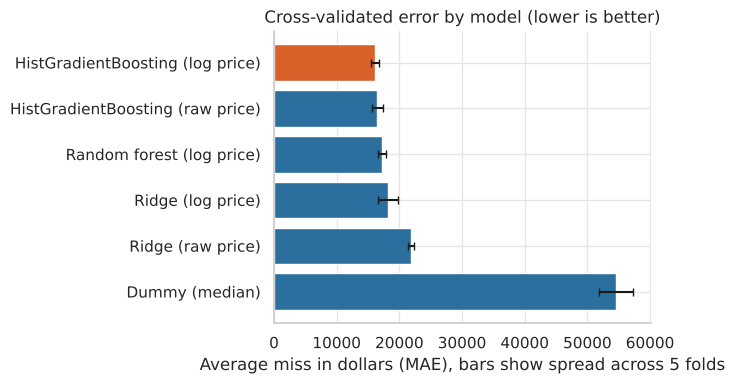

In [47]:
import matplotlib.pyplot as plt
table = pd.DataFrame(results).set_index("model").sort_values("MAE ($)", ascending=False)
best = table["MAE ($)"].idxmin()
colors = ["#D9622B" if name == best else "#2A6F9E" for name in table.index]
plt.barh(table.index, table["MAE ($)"], xerr=table["MAE spread"], color=colors, capsize=3)
plt.title("Cross-validated error by model (lower is better)")
plt.xlabel("Average miss in dollars (MAE), bars show spread across 5 folds"); plt.tight_layout(); plt.show()

**What do we learn?**
- The dummy sits far out at $54,586, and the three tree models cluster at the bottom, close together.
- **The three tree models overlap.** The forest and both boosting versions are within roughly one to two spreads of each other. We have a *group* of winners, and HistGradientBoosting on log price is only the nominal leader.
- Ridge on log price (MAE $18,146) beats raw Ridge on MAE, but its whisker is the widest apart from the dummy's.

### 8.5 Did anything fix the expensive houses?
In Stage 7, **all 21** training houses above $400,000 were predicted too low, by about **$99,000** on average. We test the promise that a log target or a tree model would help. We also score each model **without the 3 outliers**, to see how much they distort the picture.

In [48]:
big = (y_train > 400_000).values                                   # the 21 most expensive houses
keep = ~ids.loc[X_train.index].isin(outlier_ids).values            # every house except the 3 outliers
candidates = {"Ridge (raw)": build_pipeline(Ridge()), "Ridge (log)": logged(build_pipeline(Ridge())),
              "HistGB (raw)": build_pipeline(boost()), "HistGB (log)": logged(build_pipeline(boost()))}
rows = []
for name, model in candidates.items():
    p = cross_val_predict(model, X_train, y_train, cv=cv)
    rows.append({"model": name, "above $400k predicted too low (of 21)": int((p[big] < y_train.values[big]).sum()),
                 "average shortfall ($)": round((y_train.values[big] - p[big]).mean(), -3),
                 "MAE without 3 outliers ($)": round(np.abs(p - y_train.values)[keep].mean())})
print(pd.DataFrame(rows).to_string(index=False))

       model  above $400k predicted too low (of 21)  average shortfall ($)  MAE without 3 outliers ($)
 Ridge (raw)                                     21                99000.0                       20850
 Ridge (log)                                     18                64000.0                       16504
HistGB (raw)                                     15                54000.0                       15846
HistGB (log)                                     15                64000.0                       15603


**What do we learn?**
- **Better, but not fixed.** Ridge on raw price under-predicts all 21 expensive houses (average shortfall **$99,000**). The best models still under-predict **15 of 21**, with an average shortfall of about **$54,000 to $64,000**. The top end stays the hardest part of this problem, and with only 21 such houses the models have little to learn from.
- Without the 3 outliers, every model looks better (Ridge raw falls from $21,818 to **$20,850**; HistGB log from $16,132 to **$15,603**). Their effect is modest in MAE terms, and the ranking does not change.
- We carry forward **HistGradientBoosting on log price** as the lead model. It leads on every metric, even if its lead is small. At the top end HistGB on raw price is slightly better (average shortfall $54,000 against $64,000), but with only 21 houses that gap is not conclusive.

### Summary

| Model | MAE ($) | RMSE ($) | R² | Verdict |
|---|---|---|---|---|
| Dummy (median) | 54,586 | 78,860 | -0.046 | Floor |
| Ridge (raw) | 21,818 | 34,697 | 0.794 | Baseline |
| Ridge (log) | 18,146 | 39,586 | 0.681 | Better MAE, worse RMSE and R² |
| Random forest (log) | 17,265 | 28,084 | 0.867 | Trees win |
| HistGB (raw) | 16,498 | 27,792 | 0.869 | Trees win |
| **HistGB (log)** | **16,132** | **26,806** | **0.879** | **Lead model for Stage 9** |

---
### Common mistakes (Stage 8)
- **Comparing models on different folds or splits.** Use one `cv` for all, as we did.
- **Declaring a winner by a gap smaller than the spread.** The three tree models are a tie.
- **Judging by one metric.** Ridge on log price won on MAE and lost on RMSE and R². Know which metric answers the business question.
- **Comparing a log-scale score with a dollar score.** `TransformedTargetRegressor` returns dollars, so every row is comparable.
- **Trusting the training score.** The trees' training R² of about 0.98 means little. Held-out R² is the honest number.
- **Using the test set to choose a model.** It is sealed until Stage 10.
- **Forgetting `random_state` in forests and boosting.** Your numbers would change on every run.
- **Reporting the best cross-validated score as the final result.** After trying many models, the winner's CV score is a little optimistic. Stage 10's test score is the honest one.

*Try it yourself:* Change `n_estimators=200` to `20` in the random forest. How do the MAE and the fit time change?

## Stage 9: Tuning, learning curves and validation curves

**Key question this stage answers:** Is our lead model limited by too little data or by the wrong settings, and how much can tuning really gain?

### Terms used in this stage
| Term | Plain meaning |
|---|---|
| **Hyperparameter** | A setting we choose *before* training (tree depth, number of trees). The model does not learn it |
| **Bias** | Error from a model that is too simple to catch the pattern (underfitting) |
| **Variance** | Error from a model so flexible that it memorises quirks of the training houses (overfitting) |
| **Learning curve** | Score as we give the model *more training houses*. Question: would more data help? |
| **Validation curve** | Score as we change *one hyperparameter*. Question: which setting is best? |
| **Randomized search** | Try many random combinations of settings, cross-validate each, keep the best |

### 9.1 Learning curve: would more data help?
We train the lead model (HistGradientBoosting on log price) on 10% up to 100% of the training rows of each fold, and compare the training error with the cross-validated error. `n_jobs=-1` uses all your cores.

In [49]:
# Helper definitions this stage relies on (defined once here so the notebook runs top to bottom)
lead_model = logged(build_pipeline(HistGradientBoostingRegressor(random_state=RANDOM_STATE)))

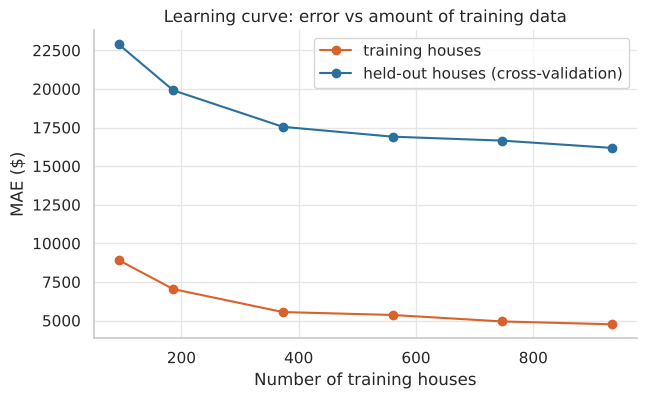

Training size -> held-out MAE: {93: 22892, 186: 19909, 373: 17546, 560: 16908, 747: 16653, 934: 16181}


In [50]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve
BLUE, ORANGE = "#2A6F9E", "#D9622B"
sizes, train_err, cv_err = learning_curve(lead_model, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error",
                                          train_sizes=[0.1, 0.2, 0.4, 0.6, 0.8, 1.0], n_jobs=-1)
plt.plot(sizes, -train_err.mean(axis=1), "o-", color=ORANGE, label="training houses")
plt.plot(sizes, -cv_err.mean(axis=1), "o-", color=BLUE, label="held-out houses (cross-validation)")
plt.title("Learning curve: error vs amount of training data"); plt.xlabel("Number of training houses"); plt.ylabel("MAE ($)")
plt.legend(); plt.show()
print("Training size -> held-out MAE:", {int(n): round(e) for n, e in zip(sizes, -cv_err.mean(axis=1))})

**What do we learn?**
- **The two lines are still apart.** With all training rows the model misses by about **$4,755** on houses it has seen and **$16,181** on new ones. A big gap means high variance (overfitting).
- **More data would help, with diminishing returns.** Held-out error falls from **$22,892** (93 houses) to **$17,546** (373) to **$16,181** (934), and the last steps give only $200-$500 each. The curve is flattening but not flat.
- **Practical meaning:** collecting 1,000 more sales would probably help a little. Better settings (next) are cheaper to try first.

### 9.2 Validation curves: which settings matter?
Two settings control how flexible a boosted-tree model is:
- `max_iter`: how many small trees to add. More trees means more detail.
- `max_depth`: how many yes/no questions deep each tree may go (`None` means no limit).

We change one at a time and keep the rest at their defaults.

max_iter -> (training MAE, held-out MAE): {'10': (24503, 26926), '25': (11400, 17815), '50': (7366, 16299), '100': (4698, 16132), '200': (2828, 16211), '400': (2101, 16270)}


max_depth -> (training MAE, held-out MAE): {'1': (16197, 17755), '2': (12406, 15697), '3': (10572, 15874), '4': (8960, 15624), '6': (7218, 15967), '8': (6309, 16066), 'None': (4698, 16132)}


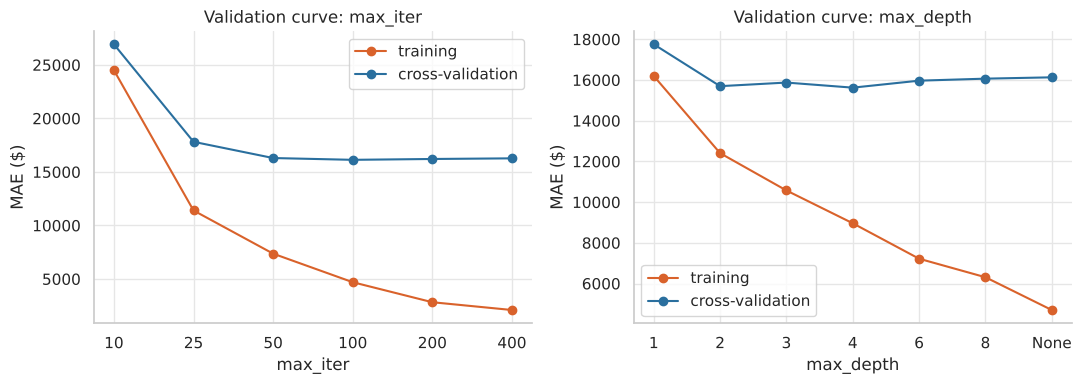

In [51]:
from sklearn.model_selection import validation_curve
P = "regressor__model__"                         # path to the model inside lead_model
tests = [("max_iter", [10, 25, 50, 100, 200, 400]), ("max_depth", [1, 2, 3, 4, 6, 8, None])]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, values) in zip(axes, tests):
    tr, te = validation_curve(lead_model, X_train, y_train, param_name=P + name, param_range=values,
                              cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
    labels = [str(v) for v in values]
    ax.plot(labels, -tr.mean(axis=1), "o-", color=ORANGE, label="training")
    ax.plot(labels, -te.mean(axis=1), "o-", color=BLUE, label="cross-validation")
    ax.set_title("Validation curve: " + name); ax.set_xlabel(name); ax.set_ylabel("MAE ($)"); ax.legend()
    print(name, "-> (training MAE, held-out MAE):", {l: (round(a), round(b)) for l, a, b in zip(labels, -tr.mean(axis=1), -te.mean(axis=1))})
plt.tight_layout(); plt.show()

**What do we learn?**
- **`max_iter`:** held-out error drops fast up to about 50 trees ($26,926 at 10, $17,815 at 25, **$16,299** at 50) and then **stays flat** ($16,132 at 100, $16,281 at 400). Here boosting does not get worse with more trees, but the training error keeps shrinking ($4,698 at 100 trees, $2,101 at 400). Extra trees only memorise.
- **`max_depth`:** very shallow trees underfit (depth 1: **$17,755**, high bias). Held-out error is best for depth 2-4 (**$15,624 to $15,874**), and worse with unlimited depth (**$16,132**). The training error keeps falling as depth grows, from $12,406 at depth 2 to $4,698 unlimited, which is the variance side.
- **Be careful reading it:** the fold-to-fold spread is about $500-$600, so depth 2, 3 and 4 are not clearly different from one another. The clear message is "very shallow is bad" and "somewhat shallow may be a bit better than unlimited".

### 9.3 Randomized search: many settings at once
Settings interact (a small learning rate needs more trees), so one-at-a-time curves can mislead. `RandomizedSearchCV` draws **20** random combinations, scores each with our 5-fold `cv`, and keeps the best.
- `learning_rate`: how big a step each new tree takes. Small steps need more trees.
- `min_samples_leaf`: the smallest number of houses allowed in a final leaf. Bigger values mean smoother, less memorising trees.
- `l2_regularization`: a penalty on extreme predictions. Bigger means more cautious.
- `loguniform` draws values evenly on a log scale, which suits settings that span orders of magnitude.

The search wraps the whole pipeline, so the encoder is refit inside every fold. It also **refits** the best settings on all training rows at the end (`best_estimator_`). Still no test set.

In [52]:
from scipy.stats import loguniform, randint
from sklearn.model_selection import RandomizedSearchCV
space = {P + "learning_rate": loguniform(0.03, 0.3), P + "max_iter": randint(100, 500),
         P + "max_depth": [2, 3, 4, 5, 6, None], P + "min_samples_leaf": randint(5, 40),
         P + "l2_regularization": loguniform(0.01, 10)}
search = RandomizedSearchCV(lead_model, space, n_iter=20, cv=cv, scoring="neg_mean_absolute_error",
                            random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
found = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
found["MAE ($)"], found["spread"] = (-found["mean_test_score"]).round(), found["std_test_score"].round()
found.columns = [c.replace("param_" + P, "") for c in found.columns]
print(found[["MAE ($)", "spread", "learning_rate", "max_iter", "max_depth", "min_samples_leaf", "l2_regularization"]].head(5).round(3).to_string(index=False))

 MAE ($)  spread  learning_rate  max_iter max_depth  min_samples_leaf  l2_regularization
 15092.0   550.0          0.144       266         2                22              3.800
 15563.0   562.0          0.036       443         2                 5              2.550
 15918.0   672.0          0.043       187         4                28              0.029
 15964.0   793.0          0.051       274      None                 7              8.342
 15976.0   609.0          0.037       289         5                25              5.829


**What do we learn?**
- **The best settings found:** a **shallow** model (`max_depth=2`), learning rate about 0.14, 266 trees, `min_samples_leaf=22` and noticeable `l2_regularization` (about 3.8). Cross-validated MAE **$15,092** against **$16,132** for the default. That is about **$1,000 (6%) better**, a bit above one spread (about $550).
- **Several shallow, cautious combinations rank near the top** (second place: depth 2, learning rate 0.04, 443 trees, **$15,563**), so the signal "shallow and regularised" is consistent, not one lucky draw.
- **Most draws did not beat the default.** Only 9 of the 20 were better than $16,132, and the middle draw scored about $16,189. Random settings are not magic: the good region has to be found.

### 9.4 The whole search as a picture
Each dot is one setting, sorted from best to worst. The dashed line is the default model.

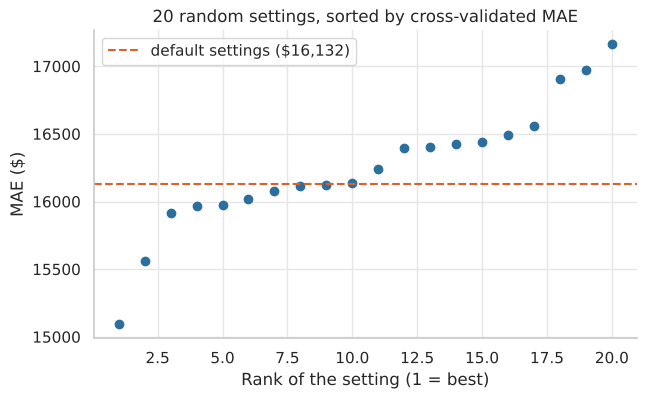

Better than default: 9 of 20 | best: $15092 | worst: $17162


In [53]:
scores = np.sort(-search.cv_results_["mean_test_score"])
plt.plot(range(1, 21), scores, "o", color=BLUE)
plt.axhline(16132, color=ORANGE, linestyle="--", label="default settings ($16,132)")
plt.title("20 random settings, sorted by cross-validated MAE"); plt.xlabel("Rank of the setting (1 = best)")
plt.ylabel("MAE ($)"); plt.legend(); plt.show()
print("Better than default:", int((scores < 16132).sum()), "of 20 | best: $%d | worst: $%d" % (scores.min(), scores.max()))

**What do we learn?**
- Only the left side of the picture is below the dashed line: **9 of 20 settings beat the default, 11 did not**, and the worst is **$17,162**. Tuning can also make things worse.
- The best dot sits **alone** below the rest ($15,092, then $15,563, then a crowd near $16,000). A winner standing apart like this deserves a second look, which we do next.

### 9.5 Is the tuned score trustworthy? A fresh-folds check
We picked the best of 20 settings *using these same 5 folds*. Some of its edge may be luck (the "winner's curse"). A cheap check is to score both models again on **different folds** (`random_state=7`) that the search never used for choosing. Same training rows, still no test set.

In [54]:
fresh_folds = KFold(n_splits=5, shuffle=True, random_state=7)       # a different shuffle than cv
rows = []
for name, model in [("Default settings", lead_model), ("Tuned settings", search.best_estimator_)]:
    out = cross_validate(model, X_train, y_train, cv=fresh_folds, return_train_score=True,
                         scoring={"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"})
    rows.append({"model": name, "MAE ($)": round(-out["test_mae"].mean()), "MAE spread": round(out["test_mae"].std()),
                 "RMSE ($)": round(-out["test_rmse"].mean()), "R2": round(out["test_r2"].mean(), 3),
                 "train R2": round(out["train_r2"].mean(), 3)})
print(pd.DataFrame(rows).to_string(index=False))

           model  MAE ($)  MAE spread  RMSE ($)    R2  train R2
Default settings    16330        1686     26552 0.881     0.984
  Tuned settings    15171        1376     25309 0.892     0.959


**What do we learn?**
- **The gain survives, but is smaller than the search claimed.** On fresh folds the default scores **$16,330** and the tuned model **$15,171**, about **$1,160 (7%) better**. RMSE improves from **$26,552 to $25,309** and R² from **0.881 to 0.892**. Reassuring.
- **A caution on the spread:** it is large ($1,686 and $1,376), so the gap is only about one spread. Treat the improvement as "probably real, modest". Stage 10 will give the final answer.
- **Overfitting shrank.** Training R² falls from **0.984 to 0.959** while held-out R² rises. The tuned model memorises less. This is the bias-variance trade-off in action: we gave up a little training accuracy for better new-house accuracy.
- **No magic for the top end.** The tuned model still under-predicts 15 of the 21 houses above $400,000 (average shortfall $67,000 against $64,000 for the default). Tuning improved the typical house, not the expensive ones.

### Summary

| Model | CV MAE ($) | Fresh-folds MAE ($) | Fresh-folds R² | Train R² |
|---|---|---|---|---|
| Default HistGB (log) | 16,132 | 16,330 | 0.881 | 0.984 |
| **Tuned HistGB (log)** | **15,092** | **15,171** | **0.892** | 0.959 |

We carry the **tuned HistGradientBoosting on log price** into Stage 10. The test set has still not been touched.

*Try it yourself:* Change `n_iter=20` to `40` and re-run the search cell. Does the best MAE improve a lot or only a little, and is the best setting still shallow?

## Stage 10: Final test evaluation and interpretation

**Key question this stage answers:** How well will our model do on houses it has never seen, and what has it learned?

### The one-time test
For nine stages the 292 test houses were sealed. We now look **once**. The rules:
- **The model is frozen.** It is the tuned HistGradientBoosting on log price from Stage 9 (`final_model`), trained on the training rows only. We do not change it after seeing the score.
- **We report the number we get**, good or bad. If we tweaked the model until the test score looked nice, the test set would become just another training set and the score would be a flattering fiction.
- **What to compare it with:** Stage 9 expected an MAE of about **$15,100**, RMSE about **$25,300** and R² about **0.89** (cross-validation). Test scores are rarely identical to those, and the gap itself is informative.
- A **DummyRegressor** (always guess the training median) shows the floor.

In [55]:
# Helper definitions this stage relies on (defined once here so the notebook runs top to bottom)
# ---- Stage 9: the tuned settings found by the randomized search (typed in so we do not repeat the search) ----
TUNED = dict(learning_rate=0.14369074394608577, max_iter=266, max_depth=2, min_samples_leaf=22,
             l2_regularization=3.8003292140451985)

def tuned_hgb():
    return HistGradientBoostingRegressor(random_state=RANDOM_STATE, **TUNED)

final_model = logged(build_pipeline(tuned_hgb())).fit(X_train, y_train)     # the Stage 10 model

In [56]:
from sklearn.dummy import DummyRegressor
dummy = DummyRegressor(strategy="median").fit(X_train, y_train)
pred_test = final_model.predict(X_test)                         # the single look at the test set
table = pd.DataFrame([report(y_test, dummy.predict(X_test), "Dummy (median)"),
                      report(y_test, pred_test, "Tuned HistGB (log price)")])
print(table.to_string(index=False))
print("Median test price: $%d | MAE as a share of it: %.1f%%" % (y_test.median(), 100 * mean_absolute_error(y_test, pred_test) / y_test.median()))

                   model  MAE ($)  RMSE ($)     R2
          Dummy (median)    59568     88667 -0.025
Tuned HistGB (log price)    16784     30796  0.876
Median test price: $154150 | MAE as a share of it: 10.9%


**What do we learn?**
- **The model works.** On houses it has never seen, the average miss (MAE) is **$16,784**, against **$59,568** for the dummy. R² is **0.876**: the model explains about 88% of the variation in sale prices. The typical miss is about **10.9%** of a typical price.
- **The test score is worse than Stage 9 promised.** MAE is **$16,784** against about $15,100 expected, and RMSE **$30,796** against about $25,300. Part of this is luck (292 houses is a small sample), and part is the "winner's curse": we picked the best of 20 settings on the same data. Expect a gap like this in real life too.
- **One house explains a lot of the gap.** The next cells find it.

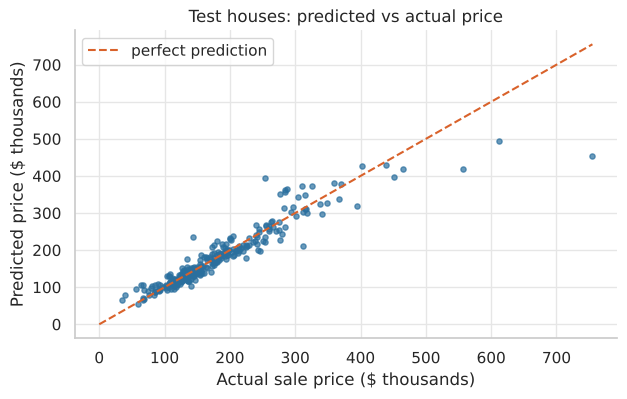

In [57]:
import matplotlib.pyplot as plt
BLUE, ORANGE = "#2A6F9E", "#D9622B"
plt.scatter(y_test / 1000, pred_test / 1000, s=14, alpha=0.7, color=BLUE)
top = max(y_test.max(), pred_test.max()) / 1000
plt.plot([0, top], [0, top], "--", color=ORANGE, label="perfect prediction")
plt.title("Test houses: predicted vs actual price"); plt.xlabel("Actual sale price ($ thousands)")
plt.ylabel("Predicted price ($ thousands)"); plt.legend(); plt.show()

**What do we learn?**
- Most dots hug the dashed line, from $50,000 to about $400,000. That is what R² of 0.876 looks like.
- The **furthest dot below the line** is a house that sold for $755,000 but was predicted at about $452,000. We look at it next.
- The spread around the line is wider for expensive houses in dollars, which is natural: a 10% miss on a $500,000 house is $50,000.

In [58]:
house_id = ids.loc[X_test.index].values
errors = pred_test - y_test.values                               # positive = we guessed too high
worst = pd.DataFrame({"Id": house_id, "actual ($)": y_test.values, "predicted ($)": pred_test.round(-3), "error ($)": errors.round(-3)})
print(worst.reindex(worst["error ($)"].abs().sort_values(ascending=False).index).head(6).to_string(index=False))
rest = house_id != 692                                           # house 692: the $755,000 sale from Stage 4
print("\nWithout house 692: MAE $%d, R2 %.3f" % (round(np.abs(errors[rest]).mean()), r2_score(y_test.values[rest], pred_test[rest])))

  Id  actual ($)  predicted ($)  error ($)
 692      755000       452000.0  -303000.0
 582      253293       394000.0   141000.0
1047      556581       420000.0  -137000.0
 899      611657       495000.0  -117000.0
 219      311500       211000.0  -101000.0
 589      143000       235000.0    92000.0

Without house 692: MAE $15802, R2 0.903


**What do we learn?**
- **House 692 is the biggest miss by far:** it sold for **$755,000** and we predicted about **$452,000**, a miss of **$303,000**. It is one of the four big houses flagged in Stage 4, and the only one that landed in the test set. The training data has almost no houses like it.
- Without that one house, MAE drops from **$16,784 to $15,802** and R² rises from **0.876 to 0.903**. That is much closer to the Stage 9 forecast. **One house moved R² by 0.03.**
- The other big misses are around $100,000 to $140,000 each. House 582 was **over**-predicted by $141,000 (sold for $253,293, predicted about $394,000), so the model does not only under-predict.
- We report **both** numbers: **$16,784** is the honest headline, and the second shows how fragile a single metric is on 292 houses. We never delete house 692 from the official score.

In [59]:
edges = y_train.quantile([1 / 3, 2 / 3]).values                  # price band edges come from TRAINING prices only
band = np.digitize(y_test.values, edges)
names = ["cheap (up to $%d)" % edges[0], "middle", "expensive (over $%d)" % edges[1]]
rows = [{"price band": names[b], "houses": int((band == b).sum()), "MAE ($)": round(np.abs(errors[band == b]).mean()),
         "miss as % of price": round(100 * (np.abs(errors[band == b]) / y_test.values[band == b]).mean(), 1),
         "average error ($)": round(errors[band == b].mean())} for b in range(3)]
print(pd.DataFrame(rows).to_string(index=False))
luxury = y_test.values > 400_000                                 # the top end that failed in Stages 7 and 8
print("\nHouses above $400,000 in the test set: %d | guessed too low: %d | average shortfall: $%d"
      % (luxury.sum(), (errors[luxury] < 0).sum(), -errors[luxury].mean()))

              price band  houses  MAE ($)  miss as % of price  average error ($)
   cheap (up to $140000)     110    10102                11.0               3411
                  middle      87    12141                 7.6               -361
expensive (over $190000)      95    28772                 9.4              -7146

Houses above $400,000 in the test set: 7 | guessed too low: 6 | average shortfall: $91956


**What do we learn?**
- **Dollar errors grow with price, percentage errors do not.** The MAE is **$10,102** for cheap houses, **$12,141** in the middle and **$28,772** for expensive ones. As a share of the price it is **11.0%, 7.6% and 9.4%**. The **cheap houses have the largest relative error**, which matters most to someone buying on a small budget.
- **The model pulls toward the middle.** Cheap houses are over-predicted by **$3,411** on average and expensive ones under-predicted by **$7,146**, while the middle band is almost unbiased (**-$361**).
- **The top end is still the weak spot.** Of the **7** houses above $400,000, **6** were guessed too low, by **$91,956** on average (house 692 is one of them). That is the same ballpark as the Ridge baseline's shortfall in Stage 7 ($98,979 on a different set of 21 houses), so tuning did not fix it. With only 7 houses we should not be more precise than that.
- Stage 11 returns to this as a **fairness and risk** question: who pays when the model is wrong?

In [60]:
cv_pred = cross_val_predict(final_model, X_train, y_train, cv=cv)    # honest predictions for training houses
low, high = np.quantile(y_train.values / cv_pred, [0.10, 0.90])      # actual price as a multiple of the prediction
inside = (y_test.values >= pred_test * low) & (y_test.values <= pred_test * high)
print("80%% price range: predicted price x %.2f to x %.2f" % (low, high))
print("Example: a prediction of $200,000 means roughly $%d to $%d" % (200_000 * low, 200_000 * high))
print("Share of TEST houses that really fell inside their range: %.1f%% (target: 80%%)" % (100 * inside.mean()))

80% price range: predicted price x 0.88 to x 1.13
Example: a prediction of $200,000 means roughly $176451 to $226971
Share of TEST houses that really fell inside their range: 78.8% (target: 80%)


**What do we learn?**
- **A price range is more useful than one number.** From the training predictions we measured how far actual prices land from our guess. Eight in ten houses sold between **0.88 and 1.13 times** the predicted price, so a $200,000 prediction means roughly **$176,000 to $227,000**.
- **The range was measured on training data, and it held up on the test set.** **78.8%** of test houses fell inside their range, close to the 80% target. The check is honest because the multipliers never saw the test houses.
- **For the business question** ("sanity-check an asking price"): an asking price far outside the range, in either direction, deserves a closer look. Inside the range, the model has no complaint. About 1 house in 5 will still sell outside it.

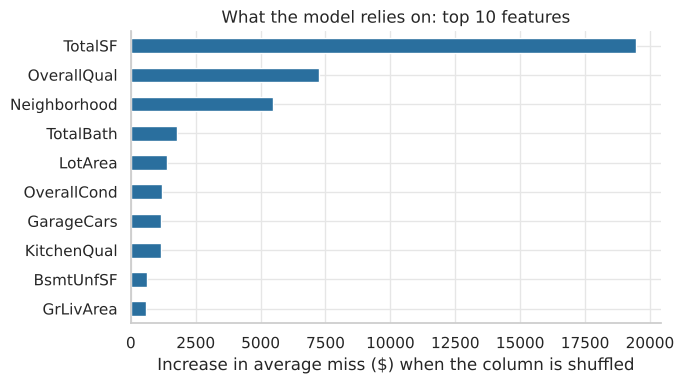

TotalSF         19447
OverallQual      7231
Neighborhood     5469
TotalBath        1770
LotArea          1378
OverallCond      1195
GarageCars       1175
KitchenQual      1162
BsmtUnfSF         641
GrLivArea         599


In [61]:
from sklearn.inspection import permutation_importance
result = permutation_importance(final_model, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE,
                                scoring="neg_mean_absolute_error", n_jobs=-1)
importance = pd.Series(result.importances_mean, index=X_test.columns).sort_values().tail(10)
importance.plot.barh(color=BLUE)
plt.title("What the model relies on: top 10 features"); plt.xlabel("Increase in average miss ($) when the column is shuffled")
plt.tight_layout(); plt.show()
print(importance.sort_values(ascending=False).round().astype(int).to_string())

**What do we learn?**
- **House size dominates.** Shuffling `TotalSF` (our Stage 5 feature) makes the average miss **$19,447** worse, almost three times the next feature. **`OverallQual`** (+$7,231) and **`Neighborhood`** (+$5,469) come next, then `TotalBath`, `LotArea`, `OverallCond`, `GarageCars` and `KitchenQual`. Size, quality and location: exactly what you would expect a buyer to say.
- **Stage 5's engineered features earned their place.** `TotalSF` and `TotalBath` are both in the top four.
- **Two cautions.** First, features that carry the same information **share** the credit: `GrLivArea` is only +$599 because `TotalSF` already covers it, so a low number does not mean a feature is unimportant. Second, importance says what the model **uses**, not what **causes** price: renovating will not raise a price by the amount shown here.

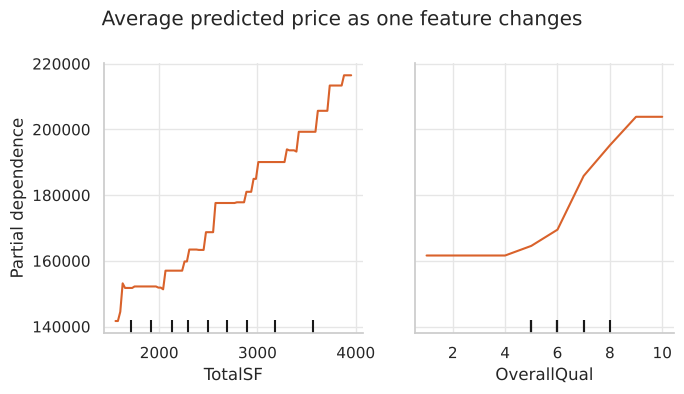

In [62]:
from sklearn.inspection import PartialDependenceDisplay
X_float = X_train.copy()
X_float[["TotalSF", "OverallQual"]] = X_float[["TotalSF", "OverallQual"]].astype(float)   # the tool needs decimals
PartialDependenceDisplay.from_estimator(final_model, X_float, ["TotalSF", "OverallQual"], line_kw={"color": ORANGE})
plt.suptitle("Average predicted price as one feature changes"); plt.tight_layout(); plt.show()

**What do we learn?**
- **Bigger house, higher price, in steps.** Moving `TotalSF` from about 1,600 to about 3,900 sq ft raises the average predicted price from roughly **$142,000 to $217,000**. The staircase shape comes from the trees: they split the data into groups instead of drawing a smooth line.
- **Quality has a threshold.** The curve is flat for `OverallQual` up to 4 (about **$162,000**), climbs fastest between 6 and 8, and levels off after about 9 (about **$204,000**) where there are very few houses.
- **How to read it:** each curve shows what the model predicts on average when we change **only that one feature** and keep every house's other features as they are. Real houses rarely change one thing alone (a bigger house usually has better finishes too), so read it as the model's logic and not as a promise of what a renovation would earn.

### Summary: our final answer

| | MAE ($) | RMSE ($) | R² |
|---|---|---|---|
| Dummy (median), test | 59,568 | 88,667 | -0.025 |
| Stage 9 forecast (cross-validation, fresh folds) | 15,171 | 25,309 | 0.892 |
| **Tuned HistGB (log price), TEST** | **16,784** | **30,796** | **0.876** |
| Same, without house 692 (for context only) | 15,802 | n/a | 0.903 |

**In plain words:** on a house we have never seen, our guess is off by about **$17,000 on average (about 11% of a typical price)**, and 8 times in 10 the real price falls within about **-12% to +13%** of the prediction. The model is trustworthy for typical houses and weak for the most expensive ones.

**What we did right:** one look at the test set, no changes afterwards, and the weak spots reported next to the good news.

*Try it yourself:* Using `errors` and `y_test`, compute the share of test houses whose miss is under 10% of their actual price. (Do not change the model afterwards. The test set has been used.)

## Stage 11: Trade-off analysis

**Key question this stage answers:** Every modelling choice gives something up. What did each of ours cost, and would we make the same choices again?

### How these experiments work
- **Each experiment changes one thing** and keeps everything else fixed.
- **Everything uses cross-validation on the training rows** (our usual 5 folds). The test set was opened once in Stage 10 and stays closed, so these experiments cannot leak into the final score.
- **Judge gaps against the `spread`.** Many differences below are smaller than the noise, and we say so when they are.

| # | Trade-off | The question |
|---|---|---|
| 11.1 | Accuracy vs interpretability and speed | Is the best model worth its complexity? |
| 11.2 | Dropping vs imputing missing data | Did Stage 4 matter? |
| 11.3 | Log target vs raw target | Who benefits from the log? |
| 11.4 | Bias vs variance | What does too simple or too flexible look like? |
| 11.5 | Dropping vs keeping outliers | Should we delete odd houses? |
| 11.6 | Fairness and risk | Who pays when the model is wrong? |

### 11.1 Accuracy vs interpretability and speed
We compare five models on the same folds. **Interpretable** means you can read *why* a prediction came out the way it did. **Predict time** is how long it takes to price 292 houses.

In [63]:
import time
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
forest = RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
contenders = [("Dummy (median)", DummyRegressor(strategy="median"), "n/a"),
              ("Ridge (log price)", logged(build_pipeline(Ridge())), "Yes (coefficients)"),
              ("Random forest (log)", logged(build_pipeline(forest)), "Partly"),
              ("HistGB default (log)", logged(build_pipeline(HistGradientBoostingRegressor(random_state=RANDOM_STATE))), "Partly"),
              ("HistGB tuned (log)", final_model, "Partly (permutation importance)")]
rows = []
for name, model, readable in contenders:
    row, fitted = score_model(model, name), clone(model).fit(X_train, y_train)
    start = time.perf_counter(); fitted.predict(X_train.iloc[:292]); seconds = time.perf_counter() - start
    rows.append({"Model": name, "MAE ($)": row["MAE ($)"], "R2": row["R2"], "Fit time (s)": row["fit s"],
                 "Predict 292 houses (s)": round(seconds, 3), "Interpretable?": readable})
print(pd.DataFrame(rows).to_string(index=False))

               Model  MAE ($)     R2  Fit time (s)  Predict 292 houses (s)                  Interpretable?
      Dummy (median)    54586 -0.046          0.00                   0.000                             n/a
   Ridge (log price)    18146  0.681          0.03                   0.010              Yes (coefficients)
 Random forest (log)    17265  0.867          1.38                   0.054                          Partly
HistGB default (log)    16132  0.879          0.61                   0.014                          Partly
  HistGB tuned (log)    15092  0.892          0.26                   0.013 Partly (permutation importance)


**What do we learn?**

| Model | MAE ($) | R² | Fit time (s) | Interpretable? |
|---|---|---|---|---|
| Dummy (median) | 54,586 | -0.046 | 0.00 | n/a |
| Ridge (log price) | 18,146 | 0.681 | 0.03 | Yes (coefficients) |
| Random forest (log) | 17,265 | 0.867 | 2.11 | Partly |
| HistGB default (log) | 16,132 | 0.879 | 0.64 | Partly |
| **HistGB tuned (log)** | **15,092** | **0.892** | **0.34** | Partly (permutation importance) |

- **Accuracy is worth its price here.** The tuned HistGB misses by **$3,054 (17%) less** than Ridge and explains far more variation (R² **0.892** against **0.681**). The cost: its answers cannot be read as simple coefficients.
- **Speed is not the issue.** Fitting takes under 3 seconds for every model, and pricing 292 houses takes under 0.1 second. Only the random forest is slow to fit (about 6 times the tuned HistGB), and it is less accurate. Your timings will differ, but the order should hold. For a few thousand predictions a day, speed would not decide this.
- **Two sentences on what we would ship:** the tuned HistGB, because it saves about $3,000 per house at negligible cost and we can still explain it with permutation importance and partial dependence (Stage 10). We would choose Ridge only if every single prediction had to come with a plain-English formula, for example for a regulator.

In [64]:
ridge = logged(build_pipeline(Ridge())).fit(X_train, y_train)
steps = ridge.regressor_.named_steps
names = steps["prep"].get_feature_names_out()
effect = pd.Series(np.expm1(steps["model"].coef_) * 100, index=names)       # % price change per +1 standard deviation
is_number = [n.startswith("num__") and "missingindicator" not in n for n in names]
top = effect[is_number].abs().sort_values(ascending=False).head(6).index
print("Ridge: % change in price for +1 standard deviation of each feature\n", effect[top].round(1).to_string())
print("\nTotalSF:", round(effect["num__TotalSF"], 1), "% | houses with MSZoning 'C (all)':", int((X_train["MSZoning"] == "C (all)").sum()),
      "| with Functional 'Sev':", int((X_train["Functional"] == "Sev").sum()))

Ridge: % change in price for +1 standard deviation of each feature
 num__OverallQual    7.6
num__GrLivArea      5.7
num__OverallCond    4.0
num__GarageCars     3.9
num__2ndFlrSF       3.5
num__1stFlrSF       3.5

TotalSF: 3.0 % | houses with MSZoning 'C (all)': 4 | with Functional 'Sev': 1


**What do we learn?**
- **Ridge is readable.** Each +1 standard deviation (a "standard deviation" is the typical spread of that feature) of `OverallQual` goes with **+7.6%** price, `GrLivArea` **+5.7%**, `OverallCond` **+4.0%** and `GarageCars` **+3.9%**. These match intuition.
- **Readable is not the same as unambiguous.** `TotalSF` shows only **+3.0%**, although Stage 10 found it by far the most important feature for the HistGB. The reason: `TotalSF` is the sum of the basement, first-floor and second-floor areas, so `1stFlrSF` (+3.5%), `2ndFlrSF` (+3.5%) and `GrLivArea` (+5.7%) share its credit. When features overlap, coefficients split the credit in ways that are easy to misread.
- **Rare categories get shaky coefficients.** Only **4** training houses have `MSZoning` "C (all)" and only **1** has `Functional` "Sev", so their coefficients are based on almost no data.

In [65]:
def pipeline_for(frame, model):
    """Same recipe as Stage 6, but built for whichever columns this version of the data has."""
    numbers = frame.select_dtypes("number").columns.tolist()
    words = frame.select_dtypes(exclude="number").columns.tolist()
    many = [c for c in words if frame[c].nunique() > 10]
    prep = ColumnTransformer([
        ("num", Pipeline([("fill", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())]), numbers),
        ("low", Pipeline([("fill", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), [c for c in words if c not in many]),
        ("high", Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                           ("target", TargetEncoder(target_type="continuous", random_state=RANDOM_STATE))]), many)])
    return logged(Pipeline([("prep", prep), ("model", model)]))
print("pipeline_for is ready")

pipeline_for is ready


### 11.2 Dropping vs imputing missing data
In Stage 4 we did not just fill gaps: for columns like `PoolQC` and `Alley`, missing meant "this house has no pool or alley", so we recorded it as `None`. We now test that decision against the two common shortcuts. We rebuild the features **without** Stage 4's fix (the "naive" versions), and also try dropping `LotFrontage`, the one column that is truly missing (it holds measurements nobody recorded).

In [66]:
raw_features = add_features(score_ratings(df.assign(MSSubClass=df["MSSubClass"].astype(str)))).drop(columns=DROP_COLS + [TARGET])
naive = raw_features.loc[X_train.index]                              # same houses, Stage 4's "absent" fix skipped
share = naive.isna().mean()
versions = {"Ours: absent recorded as None": X_train, "Naive: leave missing, impute": naive,
            "Naive: drop columns >20% missing": naive.drop(columns=share[share > 0.2].index),
            "Ours, but drop LotFrontage": X_train.drop(columns=["LotFrontage"])}
rows = []
for name, frame in versions.items():
    ridge_mae = cross_validate(pipeline_for(frame, Ridge()), frame, y_train, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)["test_score"]
    boost_mae = cross_validate(pipeline_for(frame, tuned_hgb()), frame, y_train, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)["test_score"]
    rows.append({"version": name, "columns": frame.shape[1], "Ridge MAE ($)": round(-ridge_mae.mean()),
                 "HistGB MAE ($)": round(-boost_mae.mean()), "HistGB spread": round(boost_mae.std())})
print("Columns over 20% missing in the naive version:", share[share > 0.2].round(2).to_dict(), "\n")
print(pd.DataFrame(rows).to_string(index=False))

Columns over 20% missing in the naive version: {'Alley': 0.94, 'FireplaceQu': 0.47, 'PoolQC': 0.99, 'Fence': 0.8} 

                         version  columns  Ridge MAE ($)  HistGB MAE ($)  HistGB spread
   Ours: absent recorded as None       79          18146           15092            550
    Naive: leave missing, impute       79          17841           15218            576
Naive: drop columns >20% missing       75          18020           15278            500
      Ours, but drop LotFrontage       78          18046           15170            504


**What do we learn?**
- **Honest answer: here it barely mattered.** For HistGB the four versions score **$15,092, $15,218, $15,278 and $15,170**, all within one spread (about $500 to $576) of each other. For Ridge the range is **$17,841 to $18,146**, again far inside Ridge's noise.
- **Our Stage 4 version is nominally best for HistGB**, by only $126 to $186. We cannot claim that as a win.
- **Why so little effect?** The four columns that are mostly "absent" (`PoolQC` 99%, `Alley` 94%, `Fence` 80%, `FireplaceQu` 47%) mostly say "this house has no pool, alley or fence", and the model probably gets part of that from other columns (`PoolArea`, `Fireplaces`). We did not test that explanation. `LotFrontage` is only 19% missing and carries little unique information.
- **The lesson is the method, not the winner:** we tested a cleaning decision instead of assuming it. Recording "absent" is free and honest, so we keep it, but we would not tell students it was proven necessary on this data.

In [67]:
edges = y_train.quantile([1 / 3, 2 / 3]).values; band = np.digitize(y_train.values, edges)    # cheap / middle / expensive thirds
models = {"HistGB tuned, raw price": build_pipeline(tuned_hgb()), "HistGB tuned, log price": final_model,
          "Ridge, raw price": build_pipeline(Ridge()), "Ridge, log price": logged(build_pipeline(Ridge()))}
rows = []
for name, model in models.items():
    pred = cross_val_predict(model, X_train, y_train, cv=cv); miss = np.abs(pred - y_train.values)
    percent = miss / y_train.values * 100                            # miss as a share of the house's own price
    rows.append({"model": name, "MAE ($)": round(miss.mean()), "cheap third (%)": round(percent[band == 0].mean(), 1),
                 "middle (%)": round(percent[band == 1].mean(), 1), "expensive (%)": round(percent[band == 2].mean(), 1),
                 "lowest prediction ($)": round(pred.min())})
print(pd.DataFrame(rows).to_string(index=False)); print("Cheapest real sale in the training data: $%d" % y_train.min())

                  model  MAE ($)  cheap third (%)  middle (%)  expensive (%)  lowest prediction ($)
HistGB tuned, raw price    16375             11.7         8.2            8.2                  56143
HistGB tuned, log price    15093             10.7         7.1            8.0                  59591
       Ridge, raw price    21819             17.9        12.6            9.1                   9929
       Ridge, log price    18148             11.7        11.2            8.4                  50153
Cheapest real sale in the training data: $34900


**What do we learn?**
- **For the tuned HistGB, the log target helps.** MAE is **$15,093** (log) against **$16,375** (raw), about **$1,280 (8%) lower**. The gain shows in the cheap third (**10.7%** against **11.7%** miss) and the middle third (**7.1%** against **8.2%**), and not in the expensive third (**8.0%** against **8.2%**). In Stage 8 the default HistGB showed a gap within the noise, so treat this as likely but not certain.
- **For Ridge, the log changes the picture a lot.** On raw price Ridge misses cheap houses by **17.9%** and its lowest prediction is **$9,929**, for a market where the cheapest sale was **$34,900**. On log price the cheap-third miss falls to **11.7%** and the lowest prediction is **$50,153**. Predicting in percentages keeps the model out of absurd territory on cheap houses.
- **The price of the log:** in Stage 8 Ridge on log price had a worse RMSE and R² than raw Ridge, because one huge house was predicted at $1.3 million. A log target trades small everyday misses for a risk of huge ones at the top end. The tuned HistGB did not show that problem (it had the lowest RMSE in Stage 8).

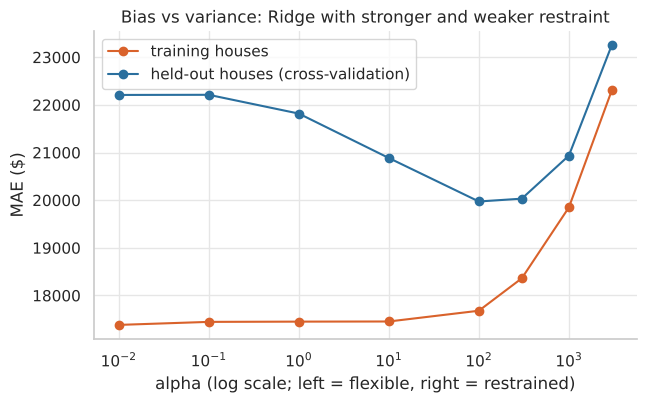

Smallest alpha: training $17382 vs held-out $22209 | largest alpha: training $22308 vs held-out $23259
Best alpha: 100 | held-out MAE: $19973


In [68]:
import matplotlib.pyplot as plt
from sklearn.model_selection import validation_curve
BLUE, ORANGE = "#2A6F9E", "#D9622B"
alphas = [0.01, 0.1, 1, 10, 100, 300, 1000, 3000]                   # alpha = how strongly Ridge is held back
train_mae, cv_mae = validation_curve(build_pipeline(Ridge()), X_train, y_train, param_name="model__alpha", param_range=alphas,
                                     cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
plt.semilogx(alphas, -train_mae.mean(axis=1), "o-", color=ORANGE, label="training houses")
plt.semilogx(alphas, -cv_mae.mean(axis=1), "o-", color=BLUE, label="held-out houses (cross-validation)")
plt.title("Bias vs variance: Ridge with stronger and weaker restraint"); plt.xlabel("alpha (log scale; left = flexible, right = restrained)")
plt.ylabel("MAE ($)"); plt.legend(); plt.show()
print("Smallest alpha: training $%d vs held-out $%d | largest alpha: training $%d vs held-out $%d"
      % (round(-train_mae.mean(axis=1)[0]), round(-cv_mae.mean(axis=1)[0]), round(-train_mae.mean(axis=1)[-1]), round(-cv_mae.mean(axis=1)[-1])))
print("Best alpha:", alphas[int(np.argmax(cv_mae.mean(axis=1)))], "| held-out MAE: $%d" % round((-cv_mae.mean(axis=1)).min()))

**What do we learn?**
- **Left side (flexible, high variance):** with almost no restraint (alpha 0.01) Ridge fits the training houses closely (**$17,382**) but misses held-out houses by **$22,209**. The gap of about **$4,800** is the sign of overfitting.
- **Right side (too restrained, high bias):** at alpha 3,000 the model is held back so much that both scores are poor and close together (**$22,308** training, **$23,259** held-out). It cannot even fit the houses it has seen, so the gap closed for the wrong reason.
- **The sweet spot is in the middle:** alpha 100 gives **$19,973** held-out, about **8% better** than the default (alpha 1 gives $21,818).
- **But restraint cannot fix the wrong model family.** Even the best Ridge is about **$4,900 worse** than the tuned HistGB ($15,092). Too-simple models are limited by bias in the model itself, which no setting can remove.

In [69]:
odd = [524, 1183, 1299]                                              # the Stage 4 outliers that are in the training rows
print(df.loc[df["Id"].isin(odd), ["Id", "SaleCondition", "GrLivArea", "SalePrice"]].to_string(index=False))
is_odd = np.isin(ids.loc[X_train.index].values, odd)
rows = []
for name, make in [("HistGB tuned (log)", lambda: final_model), ("Ridge (log)", lambda: logged(build_pipeline(Ridge()))),
                   ("Ridge (raw price)", lambda: build_pipeline(Ridge()))]:
    for drop in [False, True]:
        every_miss, normal_miss = [], []
        for fit_rows, check_rows in cv.split(X_train):
            if drop: fit_rows = fit_rows[~is_odd[fit_rows]]                # remove them from TRAINING only
            miss = np.abs(clone(make()).fit(X_train.iloc[fit_rows], y_train.iloc[fit_rows]).predict(X_train.iloc[check_rows]) - y_train.iloc[check_rows].values)
            every_miss.append(miss.mean()); normal_miss.append(miss[~is_odd[check_rows]].mean())
        rows.append({"model": name, "outliers in training": "dropped" if drop else "kept",
                     "MAE, all houses ($)": round(np.mean(every_miss)), "MAE, normal houses only ($)": round(np.mean(normal_miss))})
print(); print(pd.DataFrame(rows).to_string(index=False))

  Id SaleCondition  GrLivArea  SalePrice
 524       Partial       4676     184750
1183       Abnorml       4476     745000
1299       Partial       5642     160000



             model outliers in training  MAE, all houses ($)  MAE, normal houses only ($)
HistGB tuned (log)                 kept                15092                        14564
HistGB tuned (log)              dropped                15259                        14494
       Ridge (log)                 kept                18146                        16502
       Ridge (log)              dropped                17228                        14611
 Ridge (raw price)                 kept                21818                        20847
 Ridge (raw price)              dropped                19421                        18273


**What do we learn?**
- **The three outliers are not equally "wrong".** Houses 524 and 1299 have `SaleCondition` **Partial** (sold before completion, so the price does not describe a finished house); 1299 is 5,642 sq ft yet sold for **$160,000**. House 1183 is an **Abnorml** sale (for example a forced sale) at **$745,000**. All three are huge (4,400+ sq ft).
- **The flexible model barely cares.** For the tuned HistGB, dropping them changes the MAE on all houses from **$15,092 to $15,259** (inside the spread of about $550), and on normal houses from **$14,564 to $14,494**.
- **Simple models care a lot.** Ridge on raw price improves from **$21,818 to $19,421** (11% better) and Ridge on log price from **$18,146 to $17,228**, or **$16,502 to $14,611** on normal houses. Straight lines are dragged around by a few extreme points.
- **Why this comparison is fair:** the dropped houses remain in the validation folds, so the "all houses" column is judged on the real mix of sales. Scoring only normal houses would flatter the drop.
- **Decision:** keep them in the final model. It does not need them removed, and house 1183 shows real sales can look odd. We would only drop houses for a documented reason (an unfinished Partial sale is arguably not a normal market sale), never just because they hurt a score.

In [70]:
suburb_price = y_train.groupby(X_train["Neighborhood"]).median()      # typical price of each suburb
typical = X_train["Neighborhood"].map(suburb_price)
group = np.digitize(typical, typical.quantile([1 / 3, 2 / 3]).values)
labels = ["cheap suburbs", "mid-price suburbs", "expensive suburbs"]
pred = cross_val_predict(final_model, X_train, y_train, cv=cv)
gap = pred - y_train.values; ratio = y_train.values / pred                 # ratio outside 0.88 to 1.13 = outside the Stage 10 range
rows = [{"group": labels[g], "suburbs": X_train["Neighborhood"][group == g].nunique(), "houses": int((group == g).sum()),
         "MAE ($)": round(np.abs(gap[group == g]).mean()), "miss (% of price)": round((np.abs(gap) / y_train.values * 100)[group == g].mean(), 1),
         "average error (%)": round((gap / y_train.values * 100)[group == g].mean(), 1),
         "guessed >12% too high": round(100 * (ratio[group == g] < 0.88).mean(), 1),
         "outside 80% range": round(100 * ((ratio < 0.88) | (ratio > 1.13))[group == g].mean(), 1)} for g in range(3)]
print(pd.DataFrame(rows).to_string(index=False))

            group  suburbs  houses  MAE ($)  miss (% of price)  average error (%)  guessed >12% too high  outside 80% range
    cheap suburbs        9     352    13419               11.0                2.2                   15.1               28.4
mid-price suburbs        7     418    11811                7.3                0.4                    6.7               15.3
expensive suburbs        9     398    20021                7.7               -0.2                    9.0               19.3


**What do we learn?**
- **Cheap suburbs get the least accurate predictions where it counts.** Dollar errors are smaller there ($13,419) than in expensive suburbs ($20,021), but as a share of the price they are worse: **11.0%** against **7.3%** (mid-price) and **7.7%** (expensive). The model also **over-predicts** cheap suburbs by 2.2% on average and is about unbiased elsewhere.
- **The 80% range is not 80% everywhere.** The share of houses outside the Stage 10 range is **28.4%** in cheap suburbs, **15.3%** in mid-price and **19.3%** in expensive ones. In cheap suburbs **15.1%** of houses were guessed more than 12% too high.
- **The cost of a wrong prediction (our assumption: a buyer treats the range as a fair-price check).** Two kinds of mistake. If the model guesses too high, a fairly priced house looks like a **bargain** and the buyer may overpay: 12% on a typical cheap-suburb price of $125,000 is **$15,000**. If it guesses too low, a fair house looks **overpriced** and the buyer may walk away from a good deal, a cost that is harder to see. Overpaying usually hurts the buyer most, and it happens most often in the cheapest suburbs.
- **What we would do:** show separate ranges per price tier instead of one range for everyone, say plainly that the tool is less reliable for cheap suburbs, and collect more data there. We did not measure whether suburbs act as a stand-in for protected characteristics; before any real-world use that check would be essential.

### Summary: the trade-offs

| Trade-off | What we measured | Result | Our decision |
|---|---|---|---|
| Accuracy vs interpretability | Ridge (log) vs tuned HistGB | MAE $18,146 vs **$15,092** | Ship HistGB, explain with permutation importance |
| Accuracy vs time | Fit and predict times | Tuned HistGB fits in 0.34 s, forest 2.11 s | Time does not decide it |
| Drop vs impute missing data | Four versions of the columns | All within one spread ($15,092 to $15,278) | Keep Stage 4 (free, principled), but it did not matter here |
| Log vs raw target | By price third | Log better: $15,093 vs $16,375 | Keep the log |
| Bias vs variance | Ridge alpha curve | Best alpha 100: $19,973, still $4,900 behind HistGB | Model family matters more than restraint |
| Keep vs drop outliers | Train without 3 houses | HistGB unchanged, Ridge 5% to 11% better | Keep them for HistGB |
| Fairness and risk | Error by suburb price tier | Cheap suburbs 11.0% vs 7.3% to 7.7%, 28.4% outside the 80% range | Report per-tier ranges |

*Try it yourself:* In the missing-data cell, change `share > 0.2` to `share > 0.4`. Which columns are dropped now, and does the HistGB error change by more than its spread?

## Stage 12: Deployment

**Key question this stage answers:** How do we turn a trained model into something other people can use safely?

**Deployment** means putting the model where other programs or people can call it. Three things must travel together, or the model will misbehave in production:
- **The fitted pipeline** (the scaler, encoders and model, exactly as trained).
- **The cleaning and feature code** from Stages 4 and 5. Those are plain Python functions, not part of the scikit-learn pipeline, so a service must run them too.
- **The warnings** we learned in Stages 10 and 11: a price range, and a flag for cases where the model is weak.

**Assumption (one line):** we ship the model trained on the 1,168 training houses, so the Stage 10 score still describes it. Refitting on all 1,460 houses would add data but leave no honest score.

### 12.1 Choose when to warn
Stage 11 showed the model under-prices expensive houses. We pick a warning threshold from cross-validated predictions on the **training** houses (not the test set), balancing how many of the 21 houses above $400,000 we catch against how many houses we flag.

In [71]:
cv_pred = cross_val_predict(final_model, X_train, y_train, cv=cv)    # predictions made without seeing each house
big = y_train.values > 400_000                                        # the 21 expensive training houses
rows = [{"warn when prediction is above ($)": t, "houses flagged": int((cv_pred > t).sum()),
         "of the 21 above $400k, caught": int(((cv_pred > t) & big).sum())} for t in [300_000, 350_000, 400_000]]
print(pd.DataFrame(rows).to_string(index=False))
print("At $350,000, flagged houses that actually sold below $300,000:", int(((cv_pred > 350_000) & (y_train.values < 300_000)).sum()))

 warn when prediction is above ($)  houses flagged  of the 21 above $400k, caught
                            300000              87                             20
                            350000              38                             19
                            400000              20                             15
At $350,000, flagged houses that actually sold below $300,000: 0


**What do we learn?**
- **$350,000 is a good compromise.** It flags **38** training houses and catches **19 of the 21** that sold above $400,000. A $400,000 threshold catches only 15, and $300,000 flags 87 houses for one more catch.
- **No false alarms in the sense that matters:** none of the 38 flagged houses sold below $300,000. They really are the expensive end, where the model is least reliable.
- **A caution:** we chose this threshold using the training data, so treat it as a sensible default, not a proven rule.

### 12.2 Save one bundle
`joblib` saves Python objects to a file. We save a **bundle**: the fitted model plus everything the prediction function needs, including the scikit-learn version, so a mismatch can be caught later. A caller must send an input only if it is never missing in the training data (60 of the 79 raw columns); the other 19 may be left out.

In [72]:
import joblib, sklearn, os
raw_columns = [c for c in df.columns if c not in ("Id", TARGET)]                  # the fields a caller can send
required = [c for c in raw_columns if df[c].notna().all()]                        # never missing in training = must be sent
bundle = {"model": final_model, "price_range": (0.88, 1.13), "weak_above": 350_000,
          "raw_columns": raw_columns, "required_inputs": required,
          "known_neighborhoods": sorted(X_train["Neighborhood"].unique()),
          "sklearn_version": sklearn.__version__, "trained_on_rows": len(X_train)}
joblib.dump(bundle, "house_price_model.joblib")
print("Saved house_price_model.joblib: %.0f KB" % (os.path.getsize("house_price_model.joblib") / 1024))
print("Inputs the caller must send: %d of %d" % (len(required), len(raw_columns)), "| bundle holds:", list(bundle))

Saved house_price_model.joblib: 234 KB
Inputs the caller must send: 60 of 79 | bundle holds: ['model', 'price_range', 'weak_above', 'raw_columns', 'required_inputs', 'known_neighborhoods', 'sklearn_version', 'trained_on_rows']


In [73]:
def load_bundle(path):
    """Load the saved bundle and warn if scikit-learn has changed since it was saved."""
    saved = joblib.load(path)
    if saved["sklearn_version"] != sklearn.__version__:
        print("WARNING: saved with scikit-learn", saved["sklearn_version"], "but this is", sklearn.__version__)
    return saved

loaded = load_bundle("house_price_model.joblib")
same = np.allclose(loaded["model"].predict(X_train), final_model.predict(X_train))
print("Loaded model gives identical predictions:", same, "| trained on", loaded["trained_on_rows"], "houses")

Loaded model gives identical predictions: True | trained on 1168 houses


**What do we learn?**
- **The whole pipeline fits in one small file** (about 234 KB) and reloads in a fraction of a second. After loading it gives **identical** predictions to the model in memory. Always run this check: a saved model you have not tested is a guess.
- **Two cautions that matter in production.** First, load a model file only if you created it or fully trust its source: `joblib` files can run code when loaded, just like pickle files. Second, the scikit-learn version must match. A different version can fail or, worse, quietly change results, which is why the bundle stores the version.

### 12.3 The prediction function
This is what a service would call. It does four jobs: check the inputs, apply the **same** cleaning and features as training, predict, and add the price range and warnings. It takes one house as a dictionary of raw fields, like a row of the original file without `Id` and `SalePrice`.

In [74]:
def predict_price(house, bundle=loaded):
    """Price one house given as a dict of raw fields. Returns the price, a likely range and any warnings."""
    absent = lambda v: v is None or (isinstance(v, float) and np.isnan(v))
    missing = [c for c in bundle["required_inputs"] if absent(house.get(c))]
    if missing:
        raise ValueError("Missing required inputs: " + ", ".join(missing[:5]) + (" ..." if len(missing) > 5 else ""))
    row = pd.DataFrame([house]).reindex(columns=bundle["raw_columns"]).replace("NA", np.nan)   # unsent optional fields = missing
    features = prepare_features(row).reindex(columns=X_train.columns)                          # same cleaning and features as training
    price = float(bundle["model"].predict(features)[0])
    low, high = bundle["price_range"]; warnings = []
    if price > bundle["weak_above"]: warnings.append("Prediction above ${:,}: the model tends to under-price expensive houses.".format(bundle["weak_above"]))
    if house["Neighborhood"] not in bundle["known_neighborhoods"]: warnings.append("Neighborhood not seen in training: treat the price as a rough guess.")
    return {"predicted_price": round(price, -2), "likely_range": (round(price * low, -2), round(price * high, -2)), "warnings": warnings}
print("predict_price is ready")

predict_price is ready


In [75]:
i = X_train.index[0]; house = df.loc[i].drop(["Id", TARGET]).to_dict()     # one training house, as a plain dict
print("Function:", predict_price(house))
print("Pipeline called directly: $%.0f | actual sale price: $%d (a training house, so this is a plumbing check, not a performance test)"
      % (final_model.predict(X_train.loc[[i]])[0], y_train.loc[i]))

Function: {'predicted_price': 149200.0, 'likely_range': (131300.0, 168600.0), 'warnings': []}
Pipeline called directly: $149183 | actual sale price: $145000 (a training house, so this is a plumbing check, not a performance test)


In [76]:
unseen = dict(house, Neighborhood="Atlantis")                                  # a neighborhood the model never saw
print("Unseen neighborhood:", predict_price(unseen))
priciest = df.loc[y_train.idxmax()].drop(["Id", TARGET]).to_dict()
print("Priciest training house (sold for $%d):" % y_train.max(), predict_price(priciest))
try:
    predict_price({k: v for k, v in house.items() if k != "GrLivArea"})        # a required field is missing
except ValueError as error:
    print("Missing input ->", error)

Unseen neighborhood: {'predicted_price': 145300.0, 'likely_range': (127800.0, 164200.0), 'warnings': ['Neighborhood not seen in training: treat the price as a rough guess.']}
Priciest training house (sold for $745000): {'predicted_price': 522000.0, 'likely_range': (459300.0, 589800.0), 'warnings': ['Prediction above $350,000: the model tends to under-price expensive houses.']}
Missing input -> Missing required inputs: GrLivArea


**What do we learn?**
- **The function matches the pipeline.** It returns **$149,200** for a training house where the pipeline called directly gives **$149,183**: the same answer, rounded to the nearest $100.
- **Warnings work, and so does failing loudly.** An unseen neighborhood still gets a price (**$145,300**, against $149,200 for the real one, because the encoder falls back to the overall average) but with a warning. A missing required field raises a clear error instead of a silent guess.
- **The top end is still the weak spot.** The priciest training house sold for **$745,000** and the model says **$522,000**, even though it trained on that very house. Its "likely range" ($459,300 to $589,800) does not even contain the real price, which is why the warning says to treat expensive predictions as optimistic.
- **Speed is fine for a service:** about **26 ms** per house on this machine, mostly spent cleaning and building features rather than in the model. Your timing will differ.

In [77]:
import time
start = time.perf_counter()
for _ in range(20): predict_price(house)
print("About %.0f ms per house, including cleaning, features and the model" % ((time.perf_counter() - start) / 20 * 1000))

About 19 ms per house, including cleaning, features and the model


### 12.4 A sketch of the web service
A **web API** is a small program that waits for requests and answers them. This is a sketch to show the shape; it is **not run or tested** in this notebook, and it needs `pip install fastapi uvicorn`. Two details matter: the cleaning functions must live in a normal `.py` file that both training and the service import (functions defined in a notebook cannot be reloaded by a separate program), and the bundle is loaded **once at start-up**, not on every request.

```python
# service.py  (sketch)
import joblib
from fastapi import FastAPI, HTTPException
from housing_prep import predict_price        # your cleaning, features and predict_price, moved into housing_prep.py

app = FastAPI()
bundle = joblib.load("house_price_model.joblib")

@app.post("/predict")
def predict(house: dict):
    try:
        return predict_price(house, bundle)
    except ValueError as error:                # missing inputs become a 422 error, not a crash
        raise HTTPException(status_code=422, detail=str(error))

# run with:  uvicorn service:app
```

A request sends the house fields as JSON, and the response would look like this (numbers from our check above):

```json
{"predicted_price": 149200.0, "likely_range": [131300.0, 168600.0], "warnings": []}
```

### What could go wrong, and our guard

| Risk | Guard in this stage |
|---|---|
| Different scikit-learn version at load time | Version stored in the bundle and checked on load (pin exact versions in `requirements.txt` too) |
| Serving code cleans data differently from training | One shared `prepare_features`, plus the test that the function matches the pipeline |
| Bad or incomplete input | Required-field check with a clear error |
| Model is unreliable for some cases | Warnings for expensive predictions and unseen neighborhoods |
| Untrusted model file runs code on load | Load only files you created |
| Nobody notices the model getting worse | Not covered here: Stage 13 |

**What do we learn?**
- **Most deployment bugs are not model bugs.** They are mismatches between training and serving. Saving the pipeline, sharing the cleaning code and testing the round trip removes the common ones.
- **A deployed model should say when it is unsure.** The range and warnings are part of the product, because Stages 10 and 11 showed where the model fails.
- **Next:** the model is live, and the world will keep changing. Stage 13 shows how to notice when it stops being right.

*Try it yourself:* Call `predict_price` with `Neighborhood="NAmes "` (note the trailing space). What happens, and what check would you add to catch such typos earlier?

## Stage 13: Monitoring and drift

**Key question this stage answers:** How will we know when the model stops being right?

**Monitoring** means checking a live model regularly. A model is trained on past sales, but the world keeps moving. **Drift** is when new data stops looking like the data the model learned from. There are two kinds:
- **Data drift:** the *inputs* change. For example, only bigger houses start selling.
- **Concept drift:** the *link between inputs and price* changes. For example, the market rises and the same house sells for more.

**In the kitchen:** tomatoes taste different with the season, and guests' tastes change. A good cook keeps tasting.

**Assumption (one line):** we have no real new sales, so we use the 292 held-out houses as pretend "new sales". We do not tune or change the model here, so the Stage 10 score still stands.

**Variables needed from earlier stages:** `final_model`, `X_train`, `y_train`, `X_test`, `y_test`, `cv`, `RANDOM_STATE`.

### 13.1 Set up the pretend live stream

In [78]:
needed = ["final_model", "X_train", "y_train", "X_test", "y_test", "cv", "RANDOM_STATE"]
missing = [name for name in needed if name not in globals()]
assert not missing, "Run Stages 1-12 first. Missing: %s" % missing
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import cross_val_predict
# Pretend the 292 held-out houses are NEW sales arriving after launch (real monitoring uses real new sales).
live_pred = pd.Series(final_model.predict(X_test), index=X_test.index)
print("Live stand-in: %d houses | MAE $%s" % (len(X_test), format(round(mean_absolute_error(y_test, live_pred)), ",")))

Live stand-in: 292 houses | MAE $16,784


### 13.2 How noisy is "normal"?
An alert is only useful if it rarely fires when nothing is wrong. So first we measure normal wobble. We take errors on the **training** houses (predicted without seeing each house, using cross-validation) and draw 1,000 random batches of 60 houses, our pretend "one week of sales".

**Look for:** the typical error of a batch, and the **95th percentile**: the level that only 1 in 20 healthy batches exceeds. That becomes our alert line. We also find a normal range for **bias**, the average of (prediction minus real price). A negative bias means we are under-predicting.

In [79]:
# Reference: errors on houses the model did NOT train on (out-of-fold predictions, training houses only).
ref_pred = cross_val_predict(final_model, X_train, y_train, cv=cv)
ref_error = pd.Series(ref_pred - y_train.values, index=X_train.index)      # prediction minus real price
rng = np.random.RandomState(RANDOM_STATE)
BATCH = 60                                                                 # one "week" of new sales
mae_list, bias_list = [], []
for _ in range(1000):
    pick = rng.choice(ref_error.index, BATCH, replace=False)
    mae_list.append(ref_error[pick].abs().mean())
    bias_list.append(ref_error[pick].mean())
MAE_LINE = np.percentile(mae_list, 95)
BIAS_LOW, BIAS_HIGH = np.percentile(bias_list, [2.5, 97.5])
print("Typical 60-house MAE: $%s | alert line (95th percentile): $%s" % (format(round(np.mean(mae_list)), ","), format(round(MAE_LINE), ",")))
print("Normal bias range: $%s to $%s" % (format(round(BIAS_LOW), ","), format(round(BIAS_HIGH), ",")))

Typical 60-house MAE: $15,082 | alert line (95th percentile): $19,809
Normal bias range: $-8,759 to $4,828


Here is the same wobble as a chart.

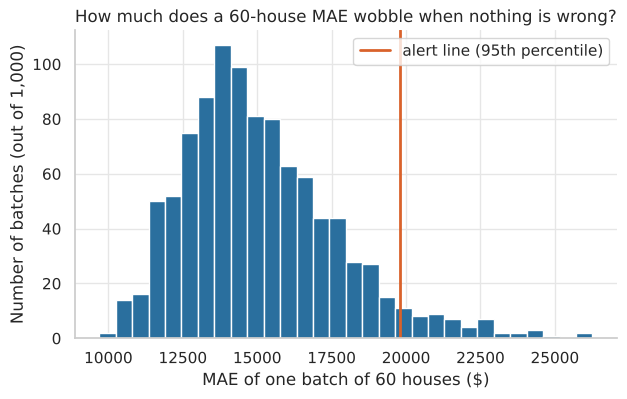

In [80]:
plt.hist(mae_list, bins=30, color="#2A6F9E")
plt.axvline(MAE_LINE, color="#D9622B", linewidth=2, label="alert line (95th percentile)")
plt.title("How much does a 60-house MAE wobble when nothing is wrong?")
plt.xlabel("MAE of one batch of 60 houses ($)"); plt.ylabel("Number of batches (out of 1,000)")
plt.legend(); plt.show()

**What do we learn?**
- **Normal errors wobble a lot.** A typical 60-house batch has an MAE of about **$15,082**, but 1 in 20 healthy batches goes above **$19,809**. That is our alert line.
- **Bias has a normal range too:** from about **−$8,759 to +$4,828**. Outside it, the model is leaning one way.
- **Small batches are noisy.** Keep this in mind: it explains a surprise coming up.

### 13.3 One function to check a batch
`monitor` does two checks:
- **Inputs (no real prices needed):** for five key features, a **KS test** (Kolmogorov-Smirnov) compares the new batch with the training houses. A small p-value (below 0.01) means the two look different. We raise an input alert if two or more features are flagged.
- **Errors (needs real prices):** the batch MAE and bias, compared with the alert line and the normal range.

In [81]:
WATCH = ["TotalSF", "OverallQual", "YearBuilt", "GrLivArea", "TotalBath"]     # inputs we keep an eye on

def monitor(batch_X, batch_y=None):
    """Check one batch of new houses. Inputs are always checked; errors only once real prices are known."""
    flagged = [c for c in WATCH if ks_2samp(X_train[c], batch_X[c]).pvalue < 0.01]   # does this input look different from training?
    report = {"drifted_inputs": flagged, "input_alert": len(flagged) >= 2}
    if batch_y is not None:
        errors = final_model.predict(batch_X) - batch_y
        report["MAE"], report["bias"] = round(errors.abs().mean()), round(errors.mean())
        report["error_alert"] = bool(report["MAE"] > MAE_LINE or not BIAS_LOW <= report["bias"] <= BIAS_HIGH)
    return report

print(monitor(X_test.iloc[:60]))      # inputs only: no real prices needed yet

{'drifted_inputs': [], 'input_alert': False}


### 13.4 Three pretend weeks
- **A:** an ordinary week.
- **B:** only the biggest houses sell (data drift).
- **C:** same houses as A, but prices are 15% higher (concept drift).

**Look for:** which check catches which problem.

In [82]:
rng2 = np.random.RandomState(RANDOM_STATE)
healthy_idx = rng2.choice(X_test.index, BATCH, replace=False)            # an ordinary week
big_idx = X_test["TotalSF"].nlargest(BATCH).index                        # a week where only the biggest houses sell
cases = {"A. Healthy week": (healthy_idx, 1.0),
         "B. Big houses sell (inputs shift)": (big_idx, 1.0),
         "C. Market up 15% (prices shift)": (healthy_idx, 1.15)}
rows = []
for name, (idx, factor) in cases.items():
    r = monitor(X_test.loc[idx], y_test.loc[idx] * factor)
    rows.append({"scenario": name, "inputs flagged": len(r["drifted_inputs"]), "input alert": r["input_alert"],
                 "MAE ($)": r["MAE"], "bias ($)": r["bias"], "error alert": r["error_alert"]})
print(pd.DataFrame(rows).to_string(index=False))

                         scenario  inputs flagged  input alert  MAE ($)  bias ($)  error alert
                  A. Healthy week               0        False    21238     -2691         True
B. Big houses sell (inputs shift)               5         True    35291     -4671         True
  C. Market up 15% (prices shift)               0        False    35276    -28379         True


**What do we learn?**
- **B (inputs shift):** all **5** watched inputs were flagged, and the MAE jumped to **$35,291**. The input check caught it, and accuracy suffered because the model is weakest on big, expensive houses (Stages 11 and 12).
- **C (prices shift):** **0** inputs were flagged, because the houses did not change. But the MAE is **$35,276** and the bias is **−$28,379**: the model under-predicts by a lot. Only the error check saw this, and it needs real sale prices, which arrive late.
- **A (the surprise):** the healthy week also raised an error alert (MAE **$21,238**, above the **$19,809** line). That is chance, not drift. Next we measure how often it happens.

### 13.5 Eight weeks of watching
Now a timeline. Weeks 1 to 4 are normal. From week 5, prices climb 4% per week. We add a rule: **retrain only after two alerts in a row**, so one noisy week does not trigger work.

In [83]:
price_factor = [1, 1, 1, 1, 1.04, 1.08, 1.12, 1.16]          # prices climb from week 5
rng3 = np.random.RandomState(RANDOM_STATE)
log = []
for week, factor in enumerate(price_factor, 1):
    idx = rng3.choice(X_test.index, BATCH, replace=False)
    r = monitor(X_test.loc[idx], y_test.loc[idx] * factor)
    log.append({"week": week, "price level": factor, "MAE ($)": r["MAE"], "bias ($)": r["bias"], "alert": r["error_alert"]})
weekly = pd.DataFrame(log)
weekly["retrain?"] = weekly["alert"] & weekly["alert"].shift(fill_value=False)      # two alerts in a row
print(weekly.to_string(index=False))

 week  price level  MAE ($)  bias ($)  alert  retrain?
    1         1.00    21238     -2691   True     False
    2         1.00    16163       298  False     False
    3         1.00    19910     -6012   True     False
    4         1.00    16580      2160  False     False
    5         1.04    17857     -7676  False     False
    6         1.08    22187    -12270   True     False
    7         1.12    27548    -24706   True      True
    8         1.16    28675    -23842   True      True


**Look for:** false alerts early on, and when the retrain rule first fires.

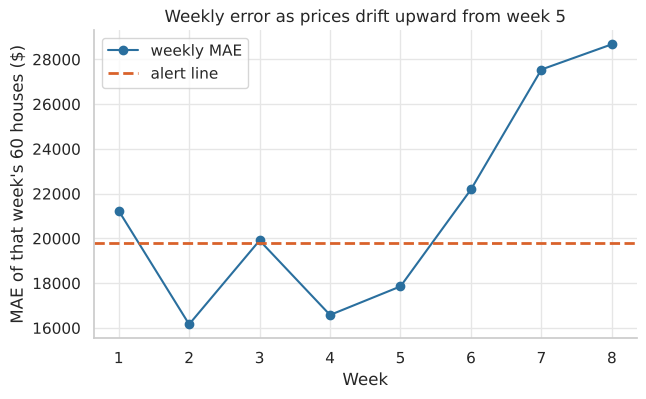

In [84]:
plt.plot(weekly["week"], weekly["MAE ($)"], marker="o", color="#2A6F9E", label="weekly MAE")
plt.axhline(MAE_LINE, color="#D9622B", linewidth=2, linestyle="--", label="alert line")
plt.title("Weekly error as prices drift upward from week 5")
plt.xlabel("Week"); plt.ylabel("MAE of that week's 60 houses ($)")
plt.legend(); plt.show()

**What do we learn?**
- **False alerts happen:** week 1 ($21,238) and week 3 ($19,910, just over the line) alerted although nothing had changed.
- **The real drift starts at week 5, but we only trigger at week 7.** Week 5 (+4%) stayed inside the limits (MAE $17,857, bias −$7,676). Alerts came in weeks 6, 7 and 8, so the rule fired in week 7, two weeks after prices began rising. Gradual drift is slow to catch with small batches.
- **Bias tells the story clearly:** it falls from −$7,676 to −$12,270, then about −$24,700 and −$23,800. The model is steadily under-predicting.

### 13.6 How often do healthy weeks alert?
Last check: how noisy is the alert itself? We draw 2,000 healthy weeks from the pretend live houses and count.

In [85]:
live_error = live_pred - y_test
rng4 = np.random.RandomState(RANDOM_STATE)
alerts = []
for _ in range(2000):                                                     # 2,000 healthy weeks
    e = live_error[rng4.choice(live_error.index, BATCH, replace=False)]
    alerts.append(e.abs().mean() > MAE_LINE or not BIAS_LOW <= e.mean() <= BIAS_HIGH)
alerts = np.array(alerts)
print("A healthy week raises an alert:      %.1f%% of the time" % (100 * alerts.mean()))
print("Two healthy weeks in a row both alert: %.1f%% of the time" % (100 * (alerts[:-1] & alerts[1:]).mean()))

A healthy week raises an alert:      19.4% of the time
Two healthy weeks in a row both alert: 4.2% of the time


**What do we learn?**
- **A single alert is too noisy.** A healthy week raises one **19.4%** of the time, roughly 1 week in 5. People ignore alarms that cry wolf.
- **Two in a row is much calmer:** **4.2%**. The price is a delay, as the 8-week timeline showed.
- **Why so high?** The alert line came from training cross-validation, but live houses score slightly worse (the same gap as Stage 10: R² 0.892 forecast vs 0.876 measured). In real life, recalibrate the line using the first few weeks of live data.
- **A caution:** our weeks are drawn from the same 292 houses and overlap, so treat these percentages as rough.

### What to do when the alert fires
1. **Check the plumbing first.** Broken data feeds, changed units and missing columns cause most alerts.
2. **Read the pattern.** Inputs only: the mix of houses changed. Errors only, with bias: the market moved.
3. **Retrain on recent sales,** then compare the new model with the old one on the same recent houses. Ship it only if it is better.
4. **Keep the old model as a fallback** until the new one proves itself.

*Try it yourself:* Change `BATCH` from 60 to 120 and rerun from cell 13.2. Does the false-alarm rate go up or down, and why?